# EdgeGuard-NS: Learned Neurosymbolic Fusion for Multi-Attack and Zero-Day
# Detection in Resource-Constrained IIoT
**Datasets:** RT-IoT2022 · NF-ToN-IoT-v2 · Edge-IIoTset

**Contributions implemented in this notebook**
1. **Learned Symbolic Evidence Fusion (LSEF), entropy-gated:** human-auditable traffic rules (flood-rate,
   half-open SYN probe, service-port, RST/ICMP logic) produce per-flow activations; each rule carries a
   **learnable evidence weight** (initialized at 0 = exact neural baseline) trained on a validation split.
   The symbolic bias is scaled by the network's normalized predictive entropy, so confident predictions are
   only negligibly perturbed and rules act mainly where the network is uncertain. Rules stay fixed and interpretable;
   the data decides their influence. Learned weights are reported as an interpretability table.
2. **Zero-day (open-set) evaluation with negative controls and OOD baselines:** an entire attack family is
   withheld from training; detection of the never-seen family is scored via neural energy vs energy
   **+ symbolic rule evidence** (AUROC and Recall @ 95% TNR). Open-set evidence weights are **non-negative
   and benign-grounded** (benign rarity only), so a rule firing can never count *against*
   detecting an unseen family. Each negative-control holdout is validated by a rule-activation diagnostic
   (<5% firing required), and the method is compared against **MSP, ODIN and Mahalanobis** under identical
   models and splits. All operating thresholds are calibrated on held-out validation benign traffic only.
3. **Classical + deep baselines under identical splits:** Random Forest, HistGradientBoosting and a compact
   1-D CNN profiled for accuracy, macro-F1, single-flow latency (single CPU thread) and serialized size,
   against our ~200 KB (FP32) / smaller INT8 model.
4. **Statistical rigor:** 10-seed protocol (fresh split + init), mean ± std everywhere, paired Wilcoxon and
   t-tests **plus bootstrap 95% CIs and Cohen's d_z** (neural vs neurosymbolic), macro-F1-first reporting for
   imbalanced classes, leak-free preprocessing, optional **temporal split** for Edge-IIoTset (session-aware
   evaluation), BN-folded INT8 deployment with numerical verification and accuracy-safety fallback.

**Revision 1 (IJCIP-D-26-00608) - additions**
- Cell 0: Colab / local environment setup (Drive output folder, dataset download).
- LSEF weights and all zero-day calibration now use the 10% early-stopping split that the network never
  trains on (`CAL_ON_HELDOUT`), instead of a sample of training rows.
- Component ablation (`RUN_ABLATION`): closed-set fusion without gates / entropy gate only / validation gate
  only; open-set evidence with uniform rule weights / AUROC-only guard. Summarised in Cell 14.
- INT8 eligibility decided on validation accuracy only; serialized model size; all baselines timed on one
  thread (Cell 10). Lightweight tree baselines: decision tree, bounded RF, LightGBM.
- Combined unsupervised zero-day detector (Isolation Forest on the benign-standardised scores) (Cell 11).
- Holdout-level (n = 6) coverage-gain Spearman with exact permutation p and family bootstrap (Cell 11b).
- Softmax calibration (ECE) before/after temperature scaling and its effect on LSEF (Cell 15).
- Results bundle for the response letter (Cell 16).


In [3]:
# Cell 0 - Environment setup (Google Colab or local)
#   Colab: mounts Drive, downloads the three datasets from Kaggle with kagglehub,
#   links each file to the exact path Cell 2 reads, and switches the working
#   directory to OUT_DIR on Drive so every CSV / figure / .pt survives a
#   runtime disconnect. Locally this cell only sets OUT_DIR = current folder.
#   Kaggle login: either add KAGGLE_USERNAME / KAGGLE_KEY in Colab Secrets
#   (key icon, enable notebook access), or log in when the prompt appears.
# --------------------------------------------------------------------------------
print('Cell 0 - Environment setup')
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    try:
        drive.mount("/content/drive")
        OUT_DIR = Path("/content/drive/MyDrive/EdgeGuardNS_rev1")
    except Exception as e:
        print(f"   WARNING: Google Drive mount failed ({type(e).__name__}: {e}). falling back to local directory.")
        OUT_DIR = Path("/content/EdgeGuardNS_rev1")

    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "kagglehub", "lightgbm"], check=False)
    OUT_DIR.mkdir(parents=True, exist_ok=True)

    import kagglehub
    try:                                               # Colab Secrets, if set
        from google.colab import userdata
        os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
        os.environ["KAGGLE_KEY"]      = userdata.get("KAGGLE_KEY")
    except Exception:
        kagglehub.login()                              # interactive login widget

    DATA_ROOT = Path("/content/kagglehub_data")
    # target path read by Cell 2 : (file name to find, Kaggle slug, version in the paper, candidate handles)
    # if all candidates fail, the slug is searched on Kaggle; or paste the handle from the
    # dataset URL (kaggle.com/datasets/<owner>/<slug>) at the front of the candidate list
    WANT = {
        "rt-iot2022real-time-internet-of-things/versions/3/RT_IOT2022.csv":
            ("RT_IOT2022.csv", "rt-iot2022real-time-internet-of-things", 3,
             ["supplejade/rt-iot2022real-time-internet-of-things"]),
        "nftoniotv2/versions/2/NF-ToN-IoT-V2.parquet":
            ("NF-ToN-IoT-V2.parquet", "nftoniotv2", 2,
             ["dhoogla/nftoniotv2"]),
        "edgeiiotset-cyber-security-dataset-of-iot-iiot/versions/5/Edge-IIoTset dataset/"
        "Selected dataset for ML and DL/ML-EdgeIIoT-dataset.csv":
            ("ML-EdgeIIoT-dataset.csv", "edgeiiotset-cyber-security-dataset-of-iot-iiot", 5,
             ["mohamedamineferrag/edgeiiotset-cyber-security-dataset-of-iot-iiot"]),
    }

    def kaggle_search(slug):
        # owner/slug handles whose slug matches, via the Kaggle CLI (uses the same credentials)
        try:
            r = subprocess.run(["kaggle", "datasets", "list", "-s", slug.replace("-", " "), "--csv"],
                               capture_output=True, text=True, timeout=120)
        except Exception:
            return []
        rows = [l.split(",")[0] for l in r.stdout.splitlines()[1:] if l.strip()]
        return [h for h in rows if h.split("/")[-1] == slug] + [h for h in rows if h.split("/")[-1] != slug]

    def fetch(slug, ver, cands):
        tried = []
        for h in cands + [c for c in kaggle_search(slug) if c not in cands]:
            for ref in (f"{h}/versions/{ver}", h):     # pinned version first, then latest
                try:
                    p = Path(kagglehub.dataset_download(ref))
                    if ref == h:
                        print(f"   WARNING: {h} version {ver} unavailable - using latest version")
                    return h, p
                except Exception as e:
                    tried.append(f"{ref} ({type(e).__name__})")
        raise RuntimeError(f"could not download '{slug}'. Tried: {tried}. Put the correct "
                           f"owner/{slug} from the Kaggle URL first in the candidate list.")

    for target, (fname, slug, ver, cands) in WANT.items():
        handle, root = fetch(slug, ver, cands)
        hits = sorted(root.rglob(fname))
        if not hits:
            raise FileNotFoundError(f"{fname} not found in {handle} ({root}); files there: "
                                    f"{[q.name for q in root.rglob('*') if q.is_file()][:20]}")
        dst = DATA_ROOT / target
        dst.parent.mkdir(parents=True, exist_ok=True)
        if dst.is_symlink() or dst.exists():
            dst.unlink()
        dst.symlink_to(hits[0])
        print(f"   {handle:70s} -> {hits[0]}  ({hits[0].stat().st_size/1e6:,.0f} MB)")
    os.environ["EDGEGUARD_DATA"] = str(DATA_ROOT)
else:
    OUT_DIR = Path(".")
os.chdir(OUT_DIR)
print(f"outputs -> {Path.cwd()} | data root -> {os.environ.get('EDGEGUARD_DATA', '(Cell 1 default)')}")
print('Cell 0 - Environment setup is complete')


Cell 0 - Environment setup


100%|██████████| 3.64M/3.64M [00:00<00:00, 200MB/s]

Extracting files...
   supplejade/rt-iot2022real-time-internet-of-things                      -> /root/.cache/kagglehub/datasets/supplejade/rt-iot2022real-time-internet-of-things/versions/3/RT_IOT2022.csv  (55 MB)


100%|██████████| 174M/174M [00:01<00:00, 120MB/s]

Extracting files...


   dhoogla/nftoniotv2                                                     -> /root/.cache/kagglehub/datasets/dhoogla/nftoniotv2/versions/2/NF-ToN-IoT-V2.parquet  (209 MB)


100%|██████████| 1.63G/1.63G [00:13<00:00, 134MB/s]

Extracting files...


   mohamedamineferrag/edgeiiotset-cyber-security-dataset-of-iot-iiot      -> /root/.cache/kagglehub/datasets/mohamedamineferrag/edgeiiotset-cyber-security-dataset-of-iot-iiot/versions/5/Edge-IIoTset dataset/Selected dataset for ML and DL/ML-EdgeIIoT-dataset.csv  (82 MB)
outputs -> /content/EdgeGuardNS_rev1 | data root -> /content/kagglehub_data
Cell 0 - Environment setup is complete


In [4]:
# Cell 1 - Imports, configuration, reproducibility, bold style
# ------------------------------------------------------------
print('Cell 1 - Imports, configuration, reproducibility, bold style')

import os, time, json, io, pickle, warnings
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")   # avoids noisy wmic traceback on Windows
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from scipy.stats import wilcoxon, ttest_rel
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import QuantileTransformer, LabelEncoder
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, IsolationForest
from sklearn.tree import DecisionTreeClassifier
from threadpoolctl import threadpool_limits
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report,
                             matthews_corrcoef, roc_auc_score, f1_score)
warnings.filterwarnings("ignore")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# data root: override with EDGEGUARD_DATA env var for reproducibility
BASE    = Path(os.environ.get("EDGEGUARD_DATA", r"F:\jupyter\kagglehub"))
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)

# experimental protocol
N_SEEDS  = 10                       # >=10 so paired Wilcoxon (min p = 2/2^n) can reach p < 0.05
SEEDS    = list(range(42, 42 + N_SEEDS))
REP_SEED = SEEDS[0]                 # representative run for per-class figures
ZD_SEEDS = SEEDS[:5]                # zero-day experiment seeds

# evaluation-honesty switches
TEMPORAL_SPLIT_EDGE   = True        # Edge-IIoTset: chronological 80/20 split (frame.time) instead of random
SINGLE_THREAD_LATENCY = True        # profile single-flow latency on ONE cpu thread ("edge-honest")
CONTROL_ACT_MAX       = 0.05        # a negative-control holdout must fire rules on <5% of its flows

# revision 1 switches
CAL_ON_HELDOUT = True              # LSEF weights + zero-day calibration on the 10% early-stopping split
                                   # (never used for gradient steps); False = original training-row sample
RUN_ABLATION   = True              # component ablation (closed-set gates, open-set weighting / guard)

# speed / size knobs
NF_MAX_PER_CLASS = 100_000          # stratified cap for NF-ToN-IoT-v2; None = all
EPOCHS     = 120
BATCH_SIZE = 4096
LR         = 2e-3
PATIENCE   = 12
MIN_EPOCHS = 25                     # early stopping cannot fire before this
H1, H2     = 256, 128               # ~50k params, ~200 KB FP32
FUSION_STEPS = 400                  # gradient steps for learned rule weights

# figures
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 13, "font.weight": "bold",
    "axes.titlesize": 15, "axes.titleweight": "bold",
    "axes.labelsize": 14, "axes.labelweight": "bold",
    "axes.linewidth": 1.8, "xtick.labelsize": 12, "ytick.labelsize": 12,
    "legend.fontsize": 12, "lines.linewidth": 2.6,
})
def bold_ticks(ax):
    for lbl in ax.get_xticklabels() + ax.get_yticklabels():
        lbl.set_fontweight("bold")

print(f"Device: {DEVICE} | PyTorch {torch.__version__} | seeds: {SEEDS} | zero-day seeds: {ZD_SEEDS}")
print(f"Temporal split (Edge-IIoTset): {TEMPORAL_SPLIT_EDGE} | single-thread latency: {SINGLE_THREAD_LATENCY}")
print(f"Calibration on held-out split: {CAL_ON_HELDOUT} | ablation: {RUN_ABLATION}")
print('Cell 1 - Imports, configuration, reproducibility, bold style is complete')


Cell 1 - Imports, configuration, reproducibility, bold style
Device: cuda | PyTorch 2.11.0+cu130 | seeds: [42, 43, 44, 45, 46, 47, 48, 49, 50, 51] | zero-day seeds: [42, 43, 44, 45, 46]
Temporal split (Edge-IIoTset): True | single-thread latency: True
Calibration on held-out split: True | ablation: True
Cell 1 - Imports, configuration, reproducibility, bold style is complete


In [5]:
# Cell 2 - Loading the three IIoT datasets
# -------------------------------------
print('Cell 2 - Load the three IIoT datasets')
t0 = time.time()

# RT-IoT2022
rt = pd.read_csv(BASE / "rt-iot2022real-time-internet-of-things/versions/3/RT_IOT2022.csv")
rt = rt.drop(columns=[c for c in ["Unnamed: 0"] if c in rt.columns])

# NF-ToN-IoT-v2  (per-class cap keeps 16.9M rows tractable; class proportions
# before/after the cap are printed so the sub-sampling is auditable)
# The label column is read first and the per-class sample is drawn exactly as
# groupby().sample(random_state=REP_SEED) would draw it on the full frame; only
# the sampled rows are then materialised, column by column (fits in ~12 GB RAM).
nf_full_counts = None
NF_PATH = BASE / "nftoniotv2/versions/2/NF-ToN-IoT-V2.parquet"
if NF_MAX_PER_CLASS is not None:
    lab = pd.read_parquet(NF_PATH, columns=["Attack"])
    nf_full_counts = lab["Attack"].value_counts()
    keep = np.concatenate([g.sample(min(len(g), NF_MAX_PER_CLASS), random_state=REP_SEED).index.values
                           for _, g in lab.groupby("Attack")])
    del lab
    import pyarrow.parquet as pq
    nf = pd.DataFrame({c: pd.read_parquet(NF_PATH, columns=[c])[c].values[keep]
                       for c in pq.ParquetFile(NF_PATH).schema_arrow.names})
    cap_tbl = pd.DataFrame({"full": nf_full_counts, "capped": nf["Attack"].value_counts()})
    print("NF-ToN-IoT-v2 per-class cap (full vs capped rows):")
    print(cap_tbl.to_string())
else:
    nf = pd.read_parquet(NF_PATH)

# Edge-IIoTset
edge = pd.read_csv(BASE / "edgeiiotset-cyber-security-dataset-of-iot-iiot/versions/5/"
                          "Edge-IIoTset dataset/Selected dataset for ML and DL/ML-EdgeIIoT-dataset.csv",
                   low_memory=False)

LABEL_COL = {"RT-IoT2022": "Attack_type", "NF-ToN-IoT-v2": "Attack", "Edge-IIoTset": "Attack_type"}
DATASETS  = {"RT-IoT2022": rt, "NF-ToN-IoT-v2": nf, "Edge-IIoTset": edge}
for name, df in DATASETS.items():
    print(f"{name:15s} rows={len(df):>9,}  cols={df.shape[1]:>3}  classes={df[LABEL_COL[name]].nunique()}")
print(f"Loaded in {time.time()-t0:.1f}s")
print('Cell 2 - Load the three IIoT datasets is complete')


Cell 2 - Load the three IIoT datasets
NF-ToN-IoT-v2 per-class cap (full vs capped rows):
               full  capped
Attack                     
Benign      3601284  100000
backdoor      16259   16259
ddos        1746590  100000
dos          654359  100000
injection    660467  100000
mitm           7723    7723
password     993718  100000
ransomware     3357    3357
scanning    3002169  100000
xss         2449955  100000
RT-IoT2022      rows=  123,117  cols= 85  classes=12
NF-ToN-IoT-v2   rows=  727,339  cols= 43  classes=10
Edge-IIoTset    rows=  157,800  cols= 63  classes=15
Loaded in 28.8s
Cell 2 - Load the three IIoT datasets is complete


Cell 3 - Leak-free preprocessing (closed/open/temporal) + Figure 1


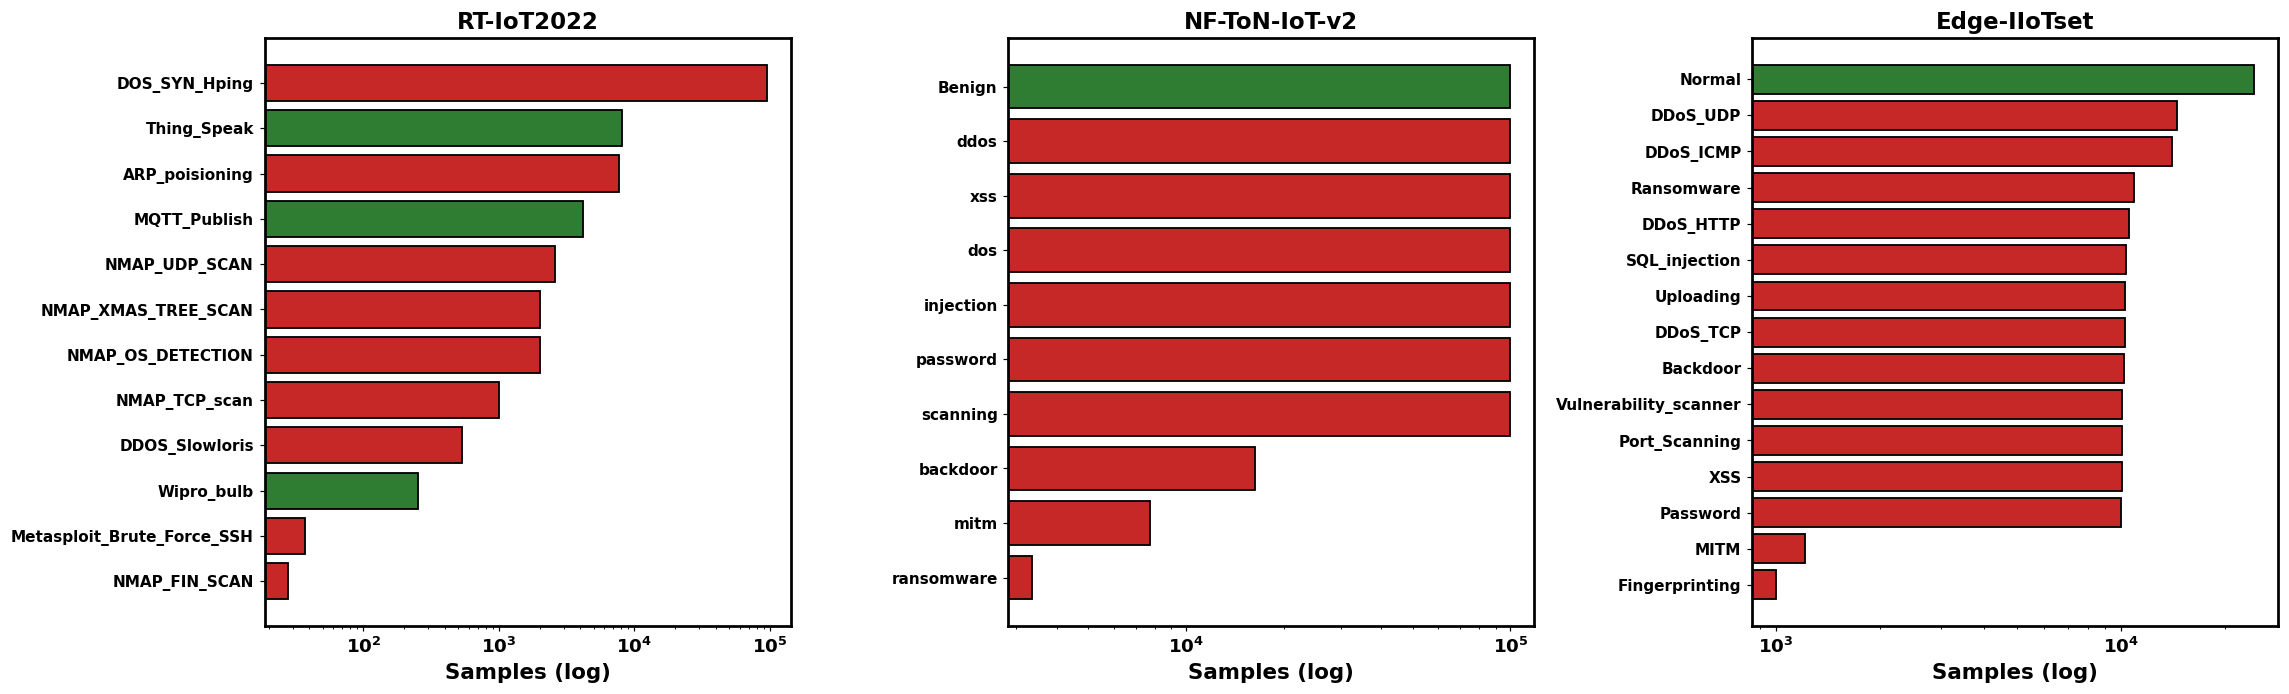

Figure 1. Class distribution across the three IIoT datasets (log scale; green = benign, red = attack).
Cell 3 - Leak-free preprocessing (closed/open/temporal) + Figure 1 is complete


In [6]:
# Cell 3 - Leak-free preprocessing (closed-set + open-set + temporal variants) + Figure 1
#   drop identifiers/IPs -> dedupe -> encode -> scale -> seed-dependent split
#   Edge-IIoTset additionally supports a CHRONOLOGICAL split (frame.time) so flows
#   from one attack session cannot straddle train and test.
# ----------------------------------------------------------------------------------------
print('Cell 3 - Leak-free preprocessing (closed/open/temporal) + Figure 1')
DROP_COLS = {
 "RT-IoT2022": [],
 "NF-ToN-IoT-v2": ["IPV4_SRC_ADDR", "IPV4_DST_ADDR", "Label"],
 "Edge-IIoTset": ["frame.time","ip.src_host","ip.dst_host","arp.src.proto_ipv4",
     "arp.dst.proto_ipv4","http.file_data","http.request.full_uri","icmp.transmit_timestamp",
     "http.request.uri.query","tcp.options","tcp.payload","tcp.srcport","tcp.dstport",
     "udp.port","mqtt.msg","Attack_label"],
}
MAX_CARD = 16

def _clean(df, label_col, drop_cols):
    df = df.drop(columns=[c for c in drop_cols if c in df.columns])
    df = df.dropna(subset=[label_col]).drop_duplicates().reset_index(drop=True)
    y_raw = df[label_col].astype(str).values
    X = df.drop(columns=[label_col])
    obj  = X.select_dtypes(include="object").columns
    keep = [c for c in obj if X[c].nunique() <= MAX_CARD]
    X = X.drop(columns=[c for c in obj if c not in keep])
    X = pd.get_dummies(X, columns=keep, dummy_na=False)
    X = X.replace([np.inf, -np.inf], np.nan).fillna(0).astype(np.float32)
    X = X.loc[:, X.std(axis=0) > 0]
    return df, X, y_raw

def _fit_scaler(Xtr, seed):
    return QuantileTransformer(n_quantiles=min(1000, len(Xtr)),
                               output_distribution="normal", subsample=200_000,
                               random_state=seed).fit(Xtr)   # rank-Gaussian: MLP-friendly heavy tails

def preprocess(df, label_col, drop_cols, seed):
    df, X, y_raw = _clean(df, label_col, drop_cols)
    le = LabelEncoder(); y = le.fit_transform(y_raw)
    Xtr, Xte, ytr, yte, rtr, rte = train_test_split(
        X.values, y, np.arange(len(y)), test_size=0.2, stratify=y, random_state=seed)
    sc = _fit_scaler(Xtr, seed)
    return dict(Xtr=sc.transform(Xtr).astype(np.float32), Xte=sc.transform(Xte).astype(np.float32),
                ytr=ytr, yte=yte, classes=le.classes_, feat_names=list(X.columns),
                raw_train=df.iloc[rtr], raw_test=df.iloc[rte])

def preprocess_temporal(df, label_col, drop_cols, seed, time_col="frame.time", min_train=10):
    # per-class chronological 80/20 split: within EACH class, the first 80% of
    # flows (by capture time) -> train, the last 20% -> test. Edge-IIoTset is
    # composed of per-attack capture sessions (each class is a contiguous time
    # block), so a GLOBAL time cut strands most classes entirely on one side;
    # the within-class cut keeps every class while still preventing flows from
    # one capture session straddling train and test (except the single session
    # at each class's boundary). Falls back to the random split when the time
    # column is unavailable.
    if time_col not in df.columns:
        print(f"   temporal split requested but '{time_col}' missing - falling back to random split")
        return preprocess(df, label_col, drop_cols, seed)
    ts = pd.to_datetime(df[time_col], errors="coerce")
    df = df.iloc[np.argsort(ts.fillna(ts.max()).values, kind="stable")].reset_index(drop=True)
    df, X, y_raw = _clean(df, label_col, drop_cols)          # order-preserving; drops time_col
    le = LabelEncoder(); y = le.fit_transform(y_raw)
    tr_list, te_list, dropped = [], [], []
    for c in np.unique(y):
        idx = np.where(y == c)[0]                            # already time-ordered
        cut = int(0.8 * len(idx))
        if cut < min_train or len(idx) - cut < 1:
            dropped.append(str(le.classes_[c])); continue
        tr_list.append(idx[:cut]); te_list.append(idx[cut:])
    tr = np.sort(np.concatenate(tr_list)); te = np.sort(np.concatenate(te_list))
    keep = np.unique(y[tr])
    remap = np.full(int(y.max()) + 1, -1, dtype=np.int64)    # integer lookup, never object dtype
    remap[keep] = np.arange(len(keep))
    if dropped:
        print(f"   temporal split: dropped classes with <{min_train} train rows: {dropped}")
    sc = _fit_scaler(X.values[tr], seed)
    return dict(Xtr=sc.transform(X.values[tr]).astype(np.float32),
                Xte=sc.transform(X.values[te]).astype(np.float32),
                ytr=remap[y[tr]], yte=remap[y[te]], classes=le.classes_[keep],
                feat_names=list(X.columns),
                raw_train=df.iloc[tr], raw_test=df.iloc[te])

def preprocess_openset(df, label_col, drop_cols, seed, holdout, cap=20_000):
    # withhold an entire attack family from training; it appears only at test time
    df, X, y_raw = _clean(df, label_col, drop_cols)
    hold_idx  = np.where(y_raw == holdout)[0]
    known_idx = np.where(y_raw != holdout)[0]
    le = LabelEncoder(); y_known = le.fit_transform(y_raw[known_idx])
    tr_i, te_i = train_test_split(np.arange(len(known_idx)), test_size=0.2,
                                  stratify=y_known, random_state=seed)
    rng = np.random.RandomState(seed)
    hold_idx = rng.choice(hold_idx, min(len(hold_idx), cap), replace=False)
    tr_g, te_g = known_idx[tr_i], known_idx[te_i]
    sc = _fit_scaler(X.values[tr_g], seed)
    return dict(Xtr=sc.transform(X.values[tr_g]).astype(np.float32), ytr=y_known[tr_i],
                Xte=sc.transform(X.values[te_g]).astype(np.float32), yte=y_known[te_i],
                Xhold=sc.transform(X.values[hold_idx]).astype(np.float32),
                classes=le.classes_, raw_train=df.iloc[tr_g], raw_test=df.iloc[te_g],
                raw_hold=df.iloc[hold_idx])

# Figure 1: class distributions (benign=green, attack=red)
BENIGN_KEYS = ("benign","normal","mqtt_publish","thing_speak","wipro","alexa")
fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
for ax, (name, df) in zip(axes, DATASETS.items()):
    counts = df[LABEL_COL[name]].astype(str).value_counts()
    colors = ["#2E7D32" if any(k in l.lower() for k in BENIGN_KEYS) else "#C62828"
              for l in counts.index]
    ax.barh(range(len(counts)), counts.values, color=colors, edgecolor="black", linewidth=1.2)
    ax.set_yticks(range(len(counts)))
    ax.set_yticklabels(counts.index, fontweight="bold", fontsize=10)
    ax.set_xscale("log"); ax.set_xlabel("Samples (log)"); ax.set_title(name)
    ax.invert_yaxis(); bold_ticks(ax)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig1_class_distribution.png"); plt.show()
print("Figure 1. Class distribution across the three IIoT datasets (log scale; green = benign, red = attack).")
print('Cell 3 - Leak-free preprocessing (closed/open/temporal) + Figure 1 is complete')


In [7]:
# Cell 4 - EdgeGuard-NS architecture: compact net + entropy-gated Learned
#          Symbolic Evidence Fusion (LSEF) + BN-folding deployment utilities
#   Rules are auditable; their evidence weights are LEARNED (init = 0,
#   i.e. exact neural baseline) on a validation split. The symbolic bias is
#   scaled by normalized predictive entropy: confident predictions are only
#   negligibly perturbed, rules act mainly where the network is uncertain.
# ---------------------------------------------------------------------------
print('Cell 4 - EdgeGuard-NS architecture (entropy-gated LSEF) + deployment utilities')

class EdgeGuardNet(nn.Module):
    def __init__(self, n_in, n_out, h1=H1, h2=H2, p=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, h1), nn.BatchNorm1d(h1), nn.ReLU(), nn.Dropout(p),
            nn.Linear(h1, h2),  nn.BatchNorm1d(h2), nn.ReLU(), nn.Dropout(p),
            nn.Linear(h2, n_out))
    def forward(self, x): return self.net(x)

class PlainMLP(nn.Module):   # deployment twin (BatchNorm folded away)
    def __init__(self, n_in, n_out, h1=H1, h2=H2):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_in, h1), nn.ReLU(),
                                 nn.Linear(h1, h2), nn.ReLU(),
                                 nn.Linear(h2, n_out))
    def forward(self, x): return self.net(x)

def fold_bn(model, n_in, n_out):
    # y = BN(Wx + b) = (s*W)x + s*(b - mean) + beta,  s = gamma / sqrt(var + eps)
    lins = [m for m in model.net if isinstance(m, nn.Linear)]
    bns  = [m for m in model.net if isinstance(m, nn.BatchNorm1d)]
    plain = PlainMLP(n_in, n_out)
    plains = [m for m in plain.net if isinstance(m, nn.Linear)]
    with torch.no_grad():
        for i, pl in enumerate(plains):
            W, b = lins[i].weight.clone(), lins[i].bias.clone()
            if i < len(bns):
                bn = bns[i]
                s = bn.weight / torch.sqrt(bn.running_var + bn.eps)
                W = W * s[:, None]; b = (b - bn.running_mean) * s + bn.bias
            pl.weight.copy_(W); pl.bias.copy_(b)
    plain.eval(); return plain

GROUPS = ["BENIGN","DOS","SCAN","BRUTE","WEB","MALWARE","MITM","OTHER"]
def class_to_group(label):
    l = label.lower()
    if any(k in l for k in ("ddos","dos","slowloris","hping","flood")):            return "DOS"
    if any(k in l for k in ("scan","nmap","recon","fingerprint","xmas","os_detection")): return "SCAN"
    if any(k in l for k in ("brute","password")):                                  return "BRUTE"
    if any(k in l for k in ("xss","injection","sql","upload")):                    return "WEB"
    if any(k in l for k in ("backdoor","ransom","malware")):                       return "MALWARE"
    if any(k in l for k in ("mitm","arp")):                                        return "MITM"
    if any(k in l for k in BENIGN_KEYS):                                           return "BENIGN"
    return "OTHER"

class SymbolicRuleEngine:
    # Fixed, human-auditable rule antecedents -> per-flow activation matrix A (n x n_rules).
    # Thresholds are percentiles of 'benign training traffic' (no test/label leakage).
    # Each rule maps to ONE group and no antecedent is duplicated across groups
    # (a duplicated antecedent double-counts a single signal).
    def __init__(self, name, raw_train, label_col):
        self.name = name
        ben_mask = np.array([class_to_group(s) == "BENIGN" for s in raw_train[label_col].astype(str)])
        ben = raw_train[ben_mask] if ben_mask.any() else raw_train
        g = lambda df, c: np.nan_to_num(df[c].astype(float).values) if c in df.columns else None
        pct = lambda v, q: float(np.nanpercentile(v, q)) if v is not None else np.inf
        self.rules = []           # (rule_name, group, callable raw_df -> activation in {0,1})
        if name == "RT-IoT2022":
            hi = pct(g(ben, "flow_pkts_per_sec"), 99.5); lo = pct(g(ben, "flow_pkts_per_sec"), 50)
            self.rules = [
             ("flood_rate>p99.5(benign)", "DOS",
              lambda r: (np.nan_to_num(r["flow_pkts_per_sec"].astype(float).values) > hi).astype(float)),
             ("SYN&slow_rate (probe)",    "SCAN",
              lambda r: ((np.nan_to_num(r["flow_SYN_flag_count"].astype(float).values) > 0) &
                         (np.nan_to_num(r["flow_pkts_per_sec"].astype(float).values) < lo)).astype(float)),
             ("dst_port in {22,23}",      "BRUTE",
              lambda r: np.isin(np.nan_to_num(r["id.resp_p"].astype(float).values), [22, 23]).astype(float)),
            ]
        elif name == "NF-ToN-IoT-v2":
            rate = (g(ben, "IN_PKTS") / (g(ben, "FLOW_DURATION_MILLISECONDS") / 1000 + 1e-3)
                    if g(ben, "IN_PKTS") is not None else None)
            hi = pct(rate, 99.5)
            self.rules = [
             ("flood_rate>p99.5(benign)", "DOS",
              lambda r: (np.nan_to_num(r["IN_PKTS"].astype(float).values) /
                         (np.nan_to_num(r["FLOW_DURATION_MILLISECONDS"].astype(float).values)/1000 + 1e-3)
                         > hi).astype(float)),
             ("pure_SYN flags==2",        "SCAN",
              lambda r: (np.nan_to_num(r["TCP_FLAGS"].astype(float).values) == 2).astype(float)),
             ("dst_port in {22,23,3389}", "BRUTE",
              lambda r: np.isin(np.nan_to_num(r["L4_DST_PORT"].astype(float).values),
                                [22, 23, 3389]).astype(float)),
             ("dst_port in {80,443,8080}","WEB",
              lambda r: np.isin(np.nan_to_num(r["L4_DST_PORT"].astype(float).values),
                                [80, 443, 8080]).astype(float)),
            ]
        else:  # Edge-IIoTset - half-open probes (SYN w/o SYN-ACK) are the classic
               # scan signature and, unlike raw SYN>0, are rare in benign TCP traffic
            self.rules = [
             ("SYN w/o SYNACK (half-open)", "SCAN",
              lambda r: ((np.nan_to_num(r["tcp.connection.syn"].astype(float).values) > 0) &
                         (np.nan_to_num(r["tcp.connection.synack"].astype(float).values) == 0)
                         ).astype(float)),
             ("tcp.connection.rst>0",       "DOS",
              lambda r: (np.nan_to_num(r["tcp.connection.rst"].astype(float).values) > 0).astype(float)),
             ("icmp.seq_le>0 (ICMP)",       "DOS",
              lambda r: (np.nan_to_num(r["icmp.seq_le"].astype(float).values) > 0).astype(float)),
            ]
        self.rule_names  = [r[0] for r in self.rules]
        self.rule_groups = [r[1] for r in self.rules]

    def activations(self, raw):
        cols = []
        for _, _, fn in self.rules:
            try:    cols.append(fn(raw))
            except KeyError: cols.append(np.zeros(len(raw)))   # missing column -> rule inactive
        return np.stack(cols, axis=1).astype(np.float32)

class LearnedFusion(nn.Module):
    # logits_final = logits + H(x) * (A * w) @ M
    #   H(x) = normalized predictive entropy in [0,1]; w init 0 => exact neural
    #   baseline. Confident samples (H ~ 0) are never perturbed, so the rules
    #   can only reshape decisions the network is already unsure about.
    def __init__(self, rule_groups, class_groups, entropy_gate=True):
        super().__init__()
        M = torch.tensor([[1.0 if cg == rg else 0.0 for cg in class_groups] for rg in rule_groups])
        self.register_buffer("M", M)                     # (n_rules, n_classes)
        self.w = nn.Parameter(torch.zeros(len(rule_groups)))
        self.entropy_gate = entropy_gate
        self._logC = float(np.log(max(M.shape[1], 2)))
    def forward(self, logits, A):
        bias = (A * self.w) @ self.M
        if self.entropy_gate:
            p = torch.softmax(logits, dim=1)
            H = -(p * torch.log(p + 1e-12)).sum(1, keepdim=True) / self._logC
            bias = H * bias
        return logits + bias

def heldout_idx(d, seed):
    # indices (into d["Xtr"]) of the 10% early-stopping split drawn inside
    # train_model (same call, same seed -> same rows). The network never takes a
    # gradient step on these rows, so they are a genuine validation split.
    _, va = train_test_split(np.arange(len(d["ytr"])), test_size=0.1,
                             stratify=d["ytr"], random_state=seed)
    return va

def train_fusion(model, d, eng, seed, steps=FUSION_STEPS, entropy_gate=True, val_gate=True, idx=None):
    # fit rule weights on one half of a validation sample; keep them ONLY if they
    # improve macro-F1 on the other half (validation gate). idx = rows of d["Xtr"]
    # to use (held-out split when CAL_ON_HELDOUT); None = original training-row sample.
    # entropy_gate / val_gate switches exist for the ablation only.
    from sklearn.metrics import f1_score as _f1
    if idx is None:
        n = len(d["ytr"]); m = min(n, 20_000, max(2_000, n // 10))
        sel = np.random.RandomState(seed).choice(n, size=m, replace=False)
    else:
        sel = np.random.RandomState(seed).permutation(idx)[:20_000]
        m = len(sel)
    fit_i, gate_i = sel[: m // 2], sel[m // 2:]
    model.eval()
    def parts(idx):
        with torch.no_grad():
            lg = model(torch.tensor(d["Xtr"][idx], device=DEVICE)).cpu()
        return lg, torch.tensor(eng.activations(d["raw_train"].iloc[idx])), torch.tensor(d["ytr"][idx])
    lg_f, A_f, y_f = parts(fit_i)
    lg_g, A_g, y_g = parts(gate_i)
    class_groups = [class_to_group(c) for c in d["classes"]]
    fus = LearnedFusion(eng.rule_groups, class_groups, entropy_gate=entropy_gate)
    n_out = len(d["classes"])
    wts = len(y_f) / (n_out * np.bincount(y_f, minlength=n_out) + 1e-9)
    crit = nn.CrossEntropyLoss(weight=torch.tensor(np.clip(wts, .2, 20), dtype=torch.float32))
    # weight decay keeps evidence weights at interpretable magnitude: without it
    # the entropy gate shrinks the effective bias and the optimizer compensates
    # with very large raw weights (|w| > 10), which defeats the rule-weight table
    opt = torch.optim.Adam(fus.parameters(), lr=0.05, weight_decay=1e-3)
    for _ in range(steps):
        opt.zero_grad(); loss = crit(fus(lg_f, A_f), y_f); loss.backward(); opt.step()
    fus.eval()
    with torch.no_grad():
        f1_plain = _f1(y_g, lg_g.argmax(1), average="macro", zero_division=0)
        f1_fused = _f1(y_g, fus(lg_g, A_g).argmax(1), average="macro", zero_division=0)
        if val_gate and f1_fused < f1_plain:
            fus.w.zero_()          # gate: revert to exact neural baseline
    return fus

def apply_fusion(fus, logits_np, A_np):
    with torch.no_grad():
        return fus(torch.tensor(logits_np), torch.tensor(A_np)).numpy()

print("EdgeGuardNet + SymbolicRuleEngine + entropy-gated LearnedFusion + BN-folding defined |",
      f"example net: {sum(p.numel() for p in EdgeGuardNet(80, 12).parameters()):,} params")
print('Cell 4 - EdgeGuard-NS architecture (entropy-gated LSEF) + deployment utilities is complete')


Cell 4 - EdgeGuard-NS architecture (entropy-gated LSEF) + deployment utilities
EdgeGuardNet + SymbolicRuleEngine + entropy-gated LearnedFusion + BN-folding defined | example net: 55,948 params
Cell 4 - EdgeGuard-NS architecture (entropy-gated LSEF) + deployment utilities is complete


In [ ]:
# Cell 5 - Fixed-seed reference run (reproducible baseline, seed = REP_SEED)
#   train_model now accepts a constructor so the deep baseline  trains
#   under the identical loop; Edge-IIoTset routes through the temporal split.
# -----------------------------------------------------------------------
print('Cell 5 - single-seed reference run')

def softmax_np(lg):
    e = np.exp(lg - lg.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)

def make_split(name, df, seed):
    if name == "Edge-IIoTset" and TEMPORAL_SPLIT_EDGE:
        return preprocess_temporal(df, LABEL_COL[name], DROP_COLS[name], seed)
    return preprocess(df, LABEL_COL[name], DROP_COLS[name], seed)

def train_model(d, name, seed, ctor=None):
    ctor = ctor or EdgeGuardNet
    torch.manual_seed(seed); np.random.seed(seed)
    Xtr, Xva, ytr, yva = train_test_split(d["Xtr"], d["ytr"], test_size=0.1,
                                          stratify=d["ytr"], random_state=seed)
    n_out = len(d["classes"])
    model = ctor(Xtr.shape[1], n_out).to(DEVICE)
    w = len(ytr) / (n_out * np.bincount(ytr, minlength=n_out) + 1e-9)
    crit  = nn.CrossEntropyLoss(weight=torch.tensor(np.clip(w, .2, 20), dtype=torch.float32, device=DEVICE))
    opt   = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=4)
    Xt, yt = torch.tensor(Xtr, device=DEVICE), torch.tensor(ytr, device=DEVICE)
    Xv, yv = torch.tensor(Xva, device=DEVICE), torch.tensor(yva, device=DEVICE)
    hist, best, wait, best_state, t0 = {"loss": [], "val_acc": []}, 0, 0, None, time.time()
    for ep in range(EPOCHS):
        model.train(); perm = torch.randperm(len(Xt), device=DEVICE); tot = 0.0
        for i in range(0, len(perm), BATCH_SIZE):
            idx = perm[i:i+BATCH_SIZE]
            if len(idx) < 2: continue
            opt.zero_grad(); loss = crit(model(Xt[idx]), yt[idx])
            loss.backward(); opt.step(); tot += loss.item() * len(idx)
        model.eval()
        with torch.no_grad():
            va = (model(Xv).argmax(1) == yv).float().mean().item()
        sched.step(va)
        hist["loss"].append(tot / len(Xt)); hist["val_acc"].append(va)
        if ep == 0 or (ep + 1) % 5 == 0:
            print(f"   {name} | seed {seed} | epoch {ep+1:>2}/{EPOCHS}  "
                  f"loss={tot/len(Xt):.4f}  val-acc={va:.4f}  ({time.time()-t0:.0f}s)", flush=True)
        if va > best:
            best, wait = va, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if ep + 1 >= MIN_EPOCHS and wait >= PATIENCE: break
    model.load_state_dict(best_state)
    print(f"   {name} | seed {seed} | early-stopped at epoch {ep+1} "
          f"(best val-acc={best:.4f})", flush=True)
    return model, hist, best, ep + 1, time.time() - t0

def metric_pack(y, lg, classes):
    pred = lg.argmax(1)
    pm, rm, f1m, _ = precision_recall_fscore_support(y, pred, average="macro",    zero_division=0)
    pw, rw, f1w, _ = precision_recall_fscore_support(y, pred, average="weighted", zero_division=0)
    try:   auc = roc_auc_score(y, softmax_np(lg), multi_class="ovr", average="macro")
    except ValueError: auc = np.nan
    # binary attack-vs-benign detection: DR/TPR, FAR/FPR, TNR, FNR
    ben = np.array([class_to_group(c) == "BENIGN" for c in classes])
    if ben.any() and (~ben).any():
        y_att, p_att = ~ben[y], ~ben[pred]
        TP = int(( y_att &  p_att).sum()); TN = int((~y_att & ~p_att).sum())
        FP = int((~y_att &  p_att).sum()); FN = int(( y_att & ~p_att).sum())
        det = dict(det_tpr=TP/max(TP+FN,1), det_tnr=TN/max(TN+FP,1),
                   det_fpr=FP/max(TN+FP,1), det_fnr=FN/max(TP+FN,1))
    else:
        det = dict(det_tpr=np.nan, det_tnr=np.nan, det_fpr=np.nan, det_fnr=np.nan)
    return dict(acc=accuracy_score(y, pred), prec_m=pm, rec_m=rm, f1_m=f1m,
                prec_w=pw, rec_w=rw, f1_w=f1w, mcc=matthews_corrcoef(y, pred),
                auc=auc, pred=pred, **det)

def evaluate(name, d, model, eng, fus):
    model.eval()
    with torch.no_grad():
        logits = model(torch.tensor(d["Xte"], device=DEVICE)).cpu().numpy()
    A_te = eng.activations(d["raw_test"])
    return {"Neural":        metric_pack(d["yte"], logits, d["classes"]),
            "Neurosymbolic": metric_pack(d["yte"], apply_fusion(fus, logits, A_te), d["classes"])}

def run_experiment(name, df, seed, keep_artifacts=False):
    d = make_split(name, df, seed)
    model, hist, best_va, n_ep, t_s = train_model(d, name, seed)
    eng = SymbolicRuleEngine(name, d["raw_train"], LABEL_COL[name])
    idx_cal = heldout_idx(d, seed) if CAL_ON_HELDOUT else None
    fus = train_fusion(model, d, eng, seed, idx=idx_cal)
    res = evaluate(name, d, model, eng, fus)
    abl = {}
    if RUN_ABLATION:              # same backbone, same split: only the fusion layer changes
        with torch.no_grad():
            lg_te = model(torch.tensor(d["Xte"], device=DEVICE)).cpu().numpy()
        A_te = eng.activations(d["raw_test"])
        for tag, eg, vg in [("no_gates", False, False), ("entropy_only", True, False),
                            ("valgate_only", False, True)]:
            f_ab = train_fusion(model, d, eng, seed, entropy_gate=eg, val_gate=vg, idx=idx_cal)
            r_ab = metric_pack(d["yte"], apply_fusion(f_ab, lg_te, A_te), d["classes"])
            abl[tag] = dict(acc=r_ab["acc"], f1_m=r_ab["f1_m"],
                            w=f_ab.w.detach().numpy().round(4).tolist())
    EXP[name].append({"seed": seed, "hist": hist, "abl": abl,
                      "w": fus.w.detach().numpy().round(4).tolist(),
                      "res": {tag: {k: v for k, v in r.items() if k != "pred"}
                              for tag, r in res.items()}})
    rs = res["Neurosymbolic"]
    print(f"{name:15s} seed={seed}  val-acc={best_va:.4f}  epochs={n_ep:>2}  "
          f"time={t_s:6.1f}s | test acc={rs['acc']*100:6.2f}%  F1m={rs['f1_m']:.4f}  "
          f"learned w={EXP[name][-1]['w']}", flush=True)
    if keep_artifacts:                       # fixed-seed run supplies all per-class figures
        DATA[name], MODELS[name] = d, model
        ENGINES[name], FUSIONS[name], RESULTS_REP[name] = eng, fus, res
    else:
        del d

EXP, DATA, MODELS, ENGINES, FUSIONS, RESULTS_REP = {n: [] for n in DATASETS}, {}, {}, {}, {}, {}
for name, df in DATASETS.items():            # ONE fixed seed: the reproducible reference
    run_experiment(name, df, REP_SEED, keep_artifacts=True)
print('Cell 5 - single-seed reference run is complete')


Cell 5 - single-seed reference run
   RT-IoT2022 | seed 42 | epoch  1/120  loss=0.8137  val-acc=0.9703  (1s)
   RT-IoT2022 | seed 42 | epoch  5/120  loss=0.1064  val-acc=0.9928  (1s)
   RT-IoT2022 | seed 42 | epoch 10/120  loss=0.0670  val-acc=0.9933  (1s)
   RT-IoT2022 | seed 42 | epoch 15/120  loss=0.0550  val-acc=0.9950  (1s)
   RT-IoT2022 | seed 42 | epoch 20/120  loss=0.0430  val-acc=0.9954  (2s)
   RT-IoT2022 | seed 42 | epoch 25/120  loss=0.0391  val-acc=0.9957  (2s)
   RT-IoT2022 | seed 42 | epoch 30/120  loss=0.0369  val-acc=0.9953  (2s)
   RT-IoT2022 | seed 42 | epoch 35/120  loss=0.0348  val-acc=0.9959  (2s)
   RT-IoT2022 | seed 42 | epoch 40/120  loss=0.0316  val-acc=0.9961  (3s)
   RT-IoT2022 | seed 42 | epoch 45/120  loss=0.0295  val-acc=0.9964  (3s)
   RT-IoT2022 | seed 42 | epoch 50/120  loss=0.0276  val-acc=0.9964  (3s)
   RT-IoT2022 | seed 42 | epoch 55/120  loss=0.0281  val-acc=0.9966  (3s)
   RT-IoT2022 | seed 42 | epoch 60/120  loss=0.0280  val-acc=0.9964  (4s)
   

In [ ]:
# Cell 6 - Multi-seed robustness protocol (additional seeds, fresh split + init)
# -------------------------------------------------------------------------------
print('Cell 6 - Multi-seed robustness protocol')
for name, df in DATASETS.items():
    for seed in SEEDS[1:]:
        run_experiment(name, df, seed, keep_artifacts=False)
print("Robustness runs recorded: " + ", ".join(f"{n}: {len(EXP[n])} seeds" for n in EXP))
print('Cell 6 - Multi-seed robustness protocol is complete')


Cell 6 - Multi-seed robustness protocol
   RT-IoT2022 | seed 43 | epoch  1/120  loss=0.8580  val-acc=0.9631  (0s)
   RT-IoT2022 | seed 43 | epoch  5/120  loss=0.0974  val-acc=0.9848  (0s)
   RT-IoT2022 | seed 43 | epoch 10/120  loss=0.0647  val-acc=0.9941  (0s)
   RT-IoT2022 | seed 43 | epoch 15/120  loss=0.0510  val-acc=0.9947  (1s)
   RT-IoT2022 | seed 43 | epoch 20/120  loss=0.0434  val-acc=0.9953  (1s)
   RT-IoT2022 | seed 43 | epoch 25/120  loss=0.0411  val-acc=0.9963  (1s)
   RT-IoT2022 | seed 43 | epoch 30/120  loss=0.0392  val-acc=0.9961  (1s)
   RT-IoT2022 | seed 43 | epoch 35/120  loss=0.0362  val-acc=0.9963  (2s)
   RT-IoT2022 | seed 43 | epoch 40/120  loss=0.0354  val-acc=0.9965  (2s)
   RT-IoT2022 | seed 43 | epoch 45/120  loss=0.0344  val-acc=0.9966  (2s)
   RT-IoT2022 | seed 43 | epoch 50/120  loss=0.0337  val-acc=0.9966  (2s)
   RT-IoT2022 | seed 43 | early-stopped at epoch 53 (best val-acc=0.9966)
RT-IoT2022      seed=43  val-acc=0.9966  epochs=53  time=   2.5s | test 

Cell 7 - Figure 2: training dynamics across all seeds


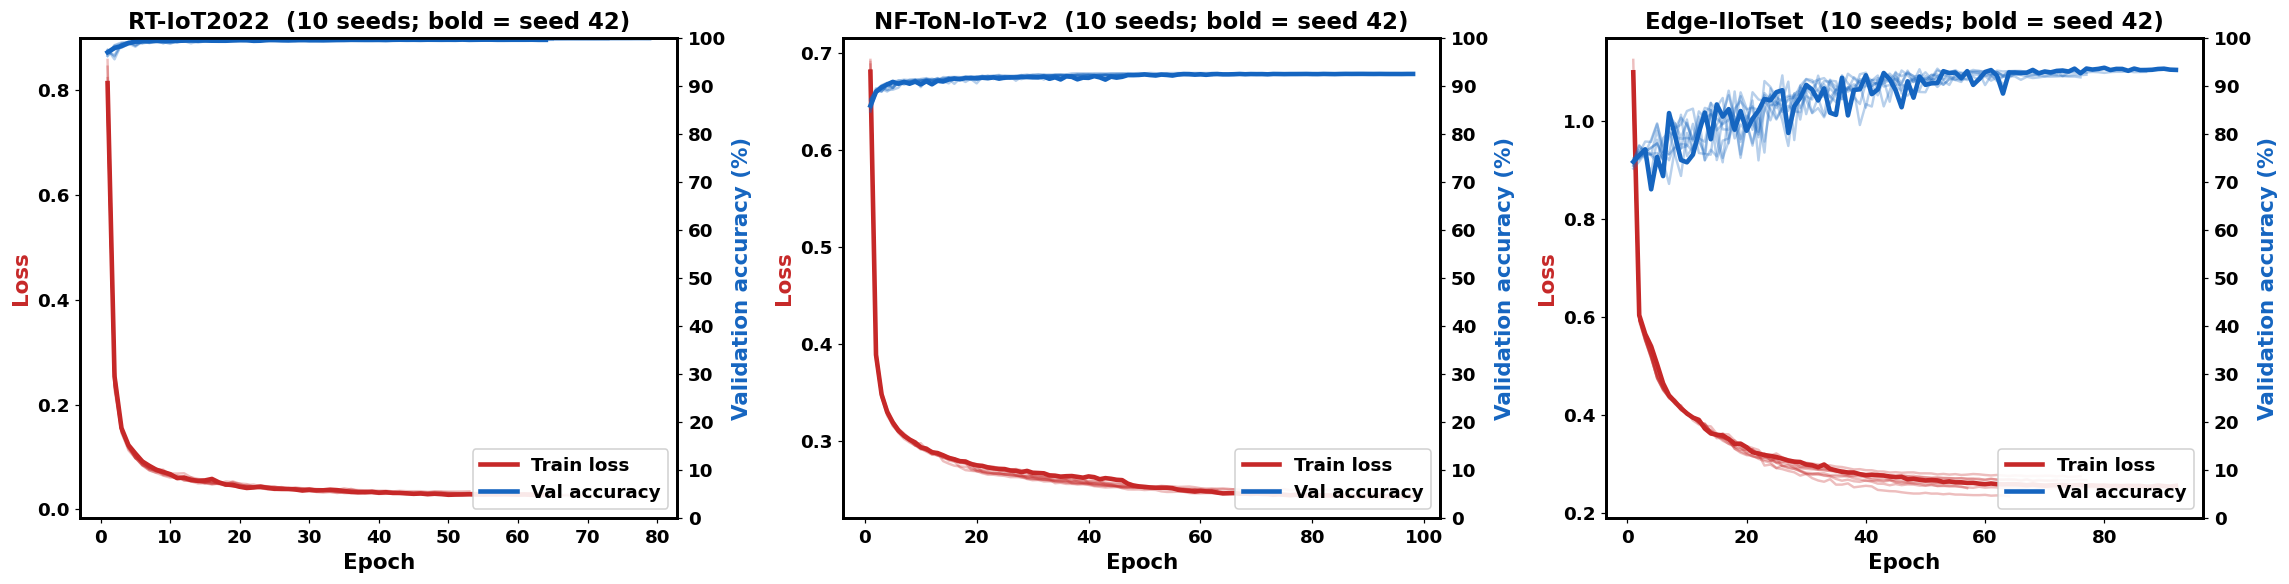

Figure 2. Training dynamics across all seeds (bold = fixed reference seed; left axis: loss, right axis: validation accuracy).
Cell 7 - Figure 2: training dynamics across all seeds is complete


In [ ]:
# Cell 7 - Figure 2: training dynamics across all seeds
# ------------------------------------------------------
print('Cell 7 - Figure 2: training dynamics across all seeds')
fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
for ax, name in zip(axes, EXP):
    ax2 = ax.twinx()
    for run in EXP[name]:
        h = run["hist"]; ep = np.arange(1, len(h["loss"]) + 1)
        rep = run["seed"] == REP_SEED
        ax.plot(ep, h["loss"], color="#C62828", alpha=1.0 if rep else 0.30,
                linewidth=3 if rep else 1.6, label="Train loss" if rep else None)
        ax2.plot(ep, np.array(h["val_acc"]) * 100, color="#1565C0",
                 alpha=1.0 if rep else 0.30, linewidth=3 if rep else 1.6,
                 label="Val accuracy" if rep else None)
    ax.set_xlabel("Epoch"); ax.set_ylabel("Loss", color="#C62828")
    ax2.set_ylabel("Validation accuracy (%)", color="#1565C0", fontweight="bold")
    ax2.set_ylim(0, 100); ax2.set_yticks(range(0, 101, 10))
    ax.set_title(f"{name}  ({len(EXP[name])} seeds; bold = seed {REP_SEED})")
    bold_ticks(ax); bold_ticks(ax2)
    lines = [l for l in ax.get_lines() + ax2.get_lines() if l.get_label()[0] != "_"]
    ax.legend(lines, [l.get_label() for l in lines], loc="lower right",
              framealpha=.9, prop={"weight": "bold"})
fig.tight_layout(); fig.savefig(FIG_DIR / "fig2_training_curves.png"); plt.show()
print("Figure 2. Training dynamics across all seeds (bold = fixed reference seed; left axis: loss, right axis: validation accuracy).")
print('Cell 7 - Figure 2: training dynamics across all seeds is complete')


In [ ]:
# Cell 8 - Aggregated metrics (mean +/- std), significance tests with bootstrap
#          95% CIs and Cohen's d_z, learned rule-weight interpretability table,
#          per-class report
# -------------------------------------------------------------------------------
print('Cell 8 - Aggregated metrics, significance tests (CIs + effect size), learned rule weights')

def agg(name, tag, key):
    v = np.array([run["res"][tag][key] for run in EXP[name]], dtype=float)
    return v.mean(), v.std()

METRIC_KEYS = [("acc","Accuracy"), ("prec_m","Precision-M"), ("rec_m","Recall-M"),
               ("f1_m","F1-Macro"), ("f1_w","F1-Weighted"), ("mcc","MCC"), ("auc","ROC-AUC")]
SIGNIF = {}
for name in EXP:
    print(f"\n{'-'*18} {name}  (mean +/- std over {len(EXP[name])} seeds) {'-'*18}")
    for tag in ("Neural", "Neurosymbolic"):
        parts = []
        for k, lab in METRIC_KEYS:
            mu, sd = agg(name, tag, k)
            parts.append(f"{lab}={mu*100:.2f}+/-{sd*100:.2f}" if k == "acc"
                         else f"{lab}={mu:.4f}+/-{sd:.4f}")
        print(f"{tag:13s} " + "  ".join(parts[:4]))
        print(f"{'':13s} " + "  ".join(parts[4:]))
    # paired significance: neural vs neurosymbolic across seeds (macro-F1 headline)
    # p-values are complemented with a paired bootstrap 95% CI on the mean
    # difference and Cohen's d_z, so claims never rest on small-n p-values alone
    SIGNIF[name] = {}
    for k, lab in [("f1_m", "F1-Macro"), ("acc", "Accuracy")]:
        a = np.array([r["res"]["Neural"][k] for r in EXP[name]])
        b = np.array([r["res"]["Neurosymbolic"][k] for r in EXP[name]])
        diff = b - a
        if np.allclose(a, b):
            wp = tp = np.nan
            verdict = "identical (learned weights ~0: symbolic evidence not useful here)"
        else:
            try:    wp = wilcoxon(a, b).pvalue
            except ValueError: wp = np.nan
            tp = ttest_rel(a, b).pvalue
            rng = np.random.RandomState(0)
            boots = np.array([rng.choice(diff, len(diff), replace=True).mean()
                              for _ in range(10_000)])
            lo, hi = np.percentile(boots, [2.5, 97.5])
            dz = diff.mean() / (diff.std(ddof=1) + 1e-12)
            verdict = (f"delta={diff.mean():+.4f} 95%CI[{lo:+.4f},{hi:+.4f}] d_z={dz:+.2f} | "
                       f"Wilcoxon p={wp:.4f}, paired t p={tp:.4f} (n={len(a)})")
        SIGNIF[name][k] = (wp, tp)
        print(f"significance [{lab}] neural vs neurosymbolic: {verdict}")
    print("learned rule evidence weights (per seed):")
    eng = ENGINES[name]
    for run in EXP[name]:
        print(f"  seed {run['seed']}: " + ", ".join(f"{n}[{g}]={w:+.3f}"
              for n, g, w in zip(eng.rule_names, eng.rule_groups, run["w"])))
    # binary attack-vs-benign detection metrics (mean +/- std over seeds)
    parts = []
    for k, lab in [("det_tpr","DR/TPR"), ("det_fpr","FAR/FPR"),
                   ("det_tnr","TNR"), ("det_fnr","FNR")]:
        mu, sd = agg(name, "Neurosymbolic", k)
        parts.append(f"{lab}={mu:.4f}+/-{sd:.4f}")
    print("attack-vs-benign detection: " + "  ".join(parts))
    print(f"\nPer-class report (representative seed {REP_SEED}, neurosymbolic):")
    print(classification_report(DATA[name]["yte"], RESULTS_REP[name]["Neurosymbolic"]["pred"],
                                target_names=DATA[name]["classes"], digits=4, zero_division=0))

# per-class one-vs-rest TP/TN/FP/FN + TPR/TNR/FPR/FNR table (rep seed, neurosymbolic)
CONF_ROWS = []
for name, d in DATA.items():
    y, pred, N = d["yte"], RESULTS_REP[name]["Neurosymbolic"]["pred"], len(d["yte"])
    print(f"\n--- {name}: per-class confusion-derived metrics (seed {REP_SEED}) ---")
    tab = []
    for ci, cls in enumerate(d["classes"]):
        TP = int(((y == ci) & (pred == ci)).sum()); FN = int(((y == ci) & (pred != ci)).sum())
        FP = int(((y != ci) & (pred == ci)).sum()); TN = N - TP - FN - FP
        row = dict(Dataset=name, Class=cls, TP=TP, TN=TN, FP=FP, FN=FN,
                   TPR=round(TP/max(TP+FN,1),4), TNR=round(TN/max(TN+FP,1),4),
                   FPR=round(FP/max(TN+FP,1),4), FNR=round(FN/max(TP+FN,1),4),
                   Precision=round(TP/max(TP+FP,1),4))
        tab.append(row); CONF_ROWS.append(row)
    print(pd.DataFrame(tab).drop(columns="Dataset").to_string(index=False))
pd.DataFrame(CONF_ROWS).to_csv("perclass_confusion_metrics.csv", index=False)
print("\nper-class TP/TN/FP/FN table saved -> perclass_confusion_metrics.csv")
print('Cell 8 - Aggregated metrics, significance tests, learned rule weights is complete')


Cell 8 - Aggregated metrics, significance tests (CIs + effect size), learned rule weights

------------------ RT-IoT2022  (mean +/- std over 10 seeds) ------------------
Neural        Accuracy=99.66+/-0.04  Precision-M=0.9375+/-0.0106  Recall-M=0.9642+/-0.0097  F1-Macro=0.9468+/-0.0057
              F1-Weighted=0.9966+/-0.0004  MCC=0.9914+/-0.0009  ROC-AUC=0.9989+/-0.0028
Neurosymbolic Accuracy=99.66+/-0.04  Precision-M=0.9375+/-0.0106  Recall-M=0.9642+/-0.0097  F1-Macro=0.9468+/-0.0057
              F1-Weighted=0.9966+/-0.0004  MCC=0.9914+/-0.0009  ROC-AUC=0.9989+/-0.0028
significance [F1-Macro] neural vs neurosymbolic: identical (learned weights ~0: symbolic evidence not useful here)
significance [Accuracy] neural vs neurosymbolic: identical (learned weights ~0: symbolic evidence not useful here)
learned rule evidence weights (per seed):
  seed 42: flood_rate>p99.5(benign)[DOS]=+0.211, SYN&slow_rate (probe)[SCAN]=-0.016, dst_port in {22,23}[BRUTE]=+0.000
  seed 43: flood_rate>p99.5(b

Cell 9 - Figure 3: confusion matrices | Figure 4: per-class F1


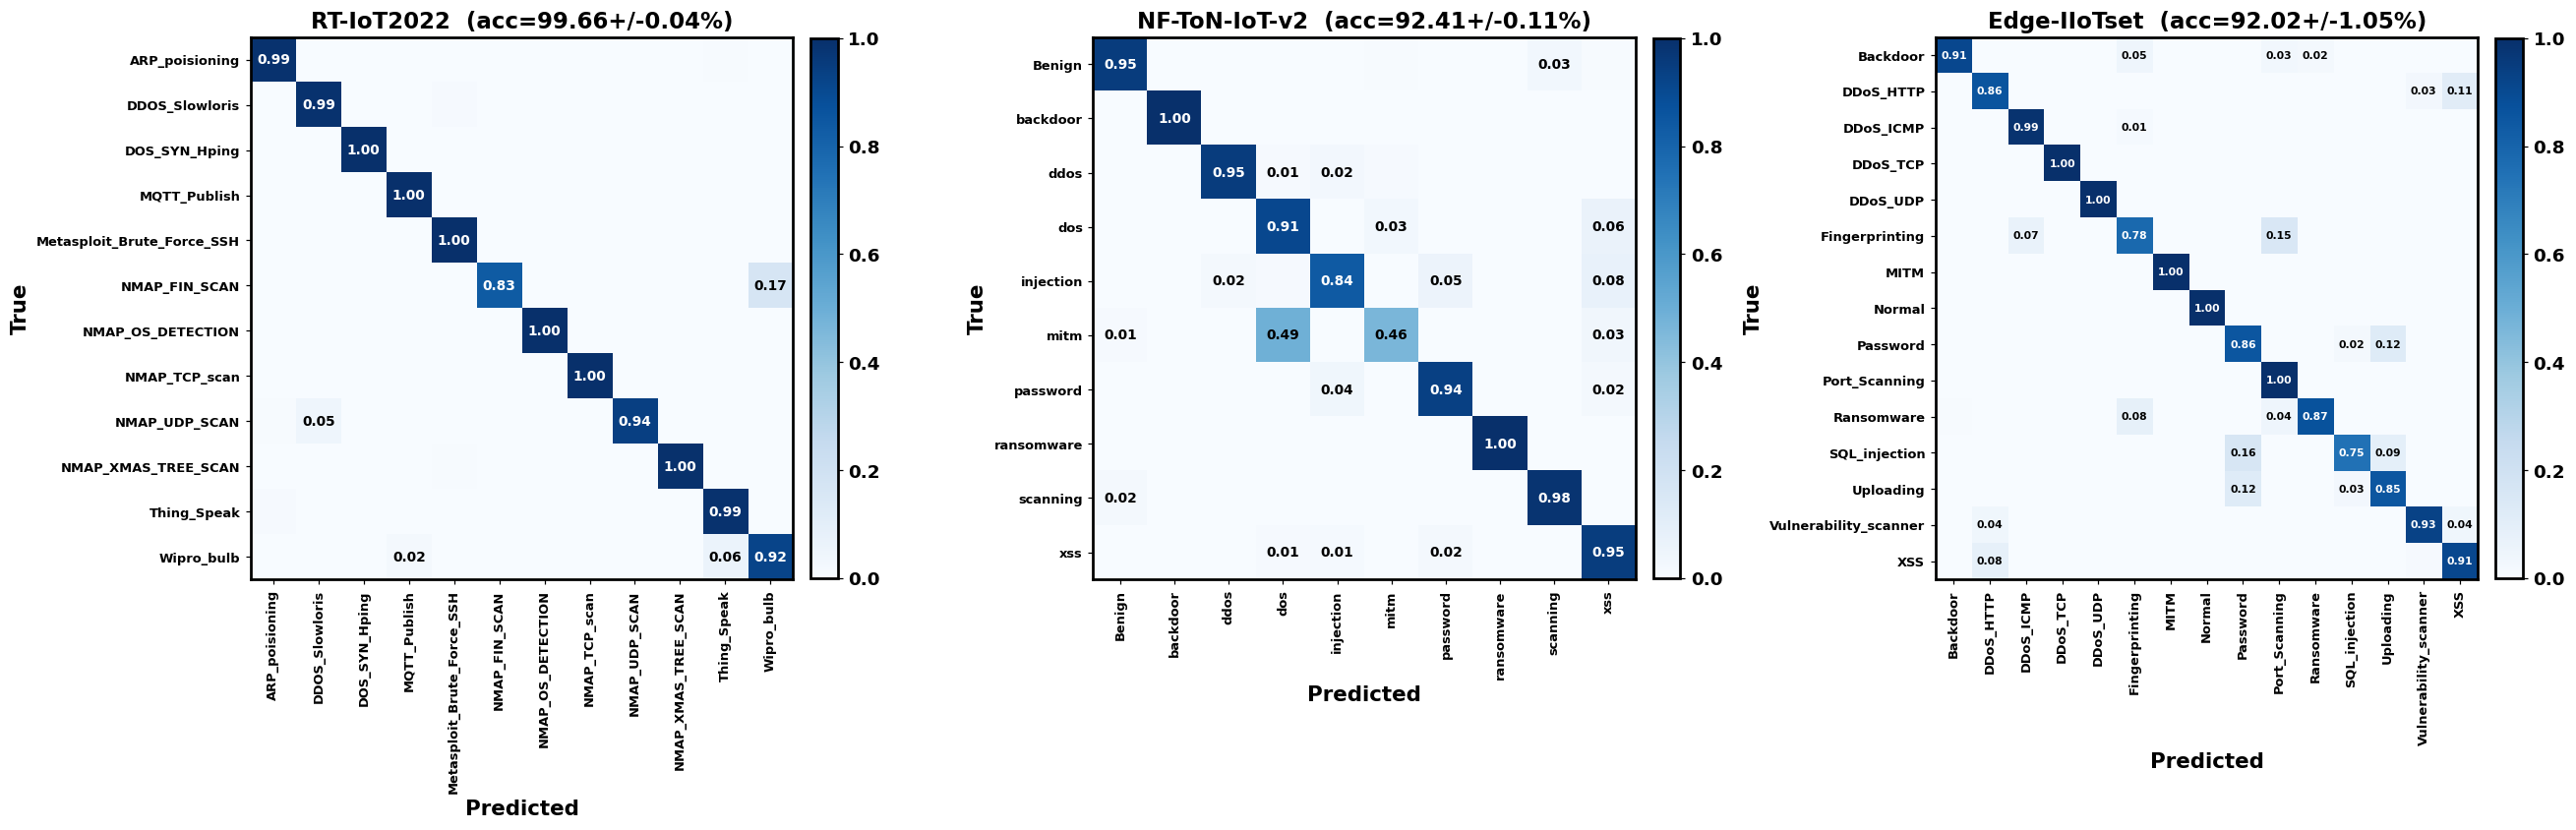

Figure 3. Row-normalized confusion matrices of the neurosymbolic model (fixed reference seed).


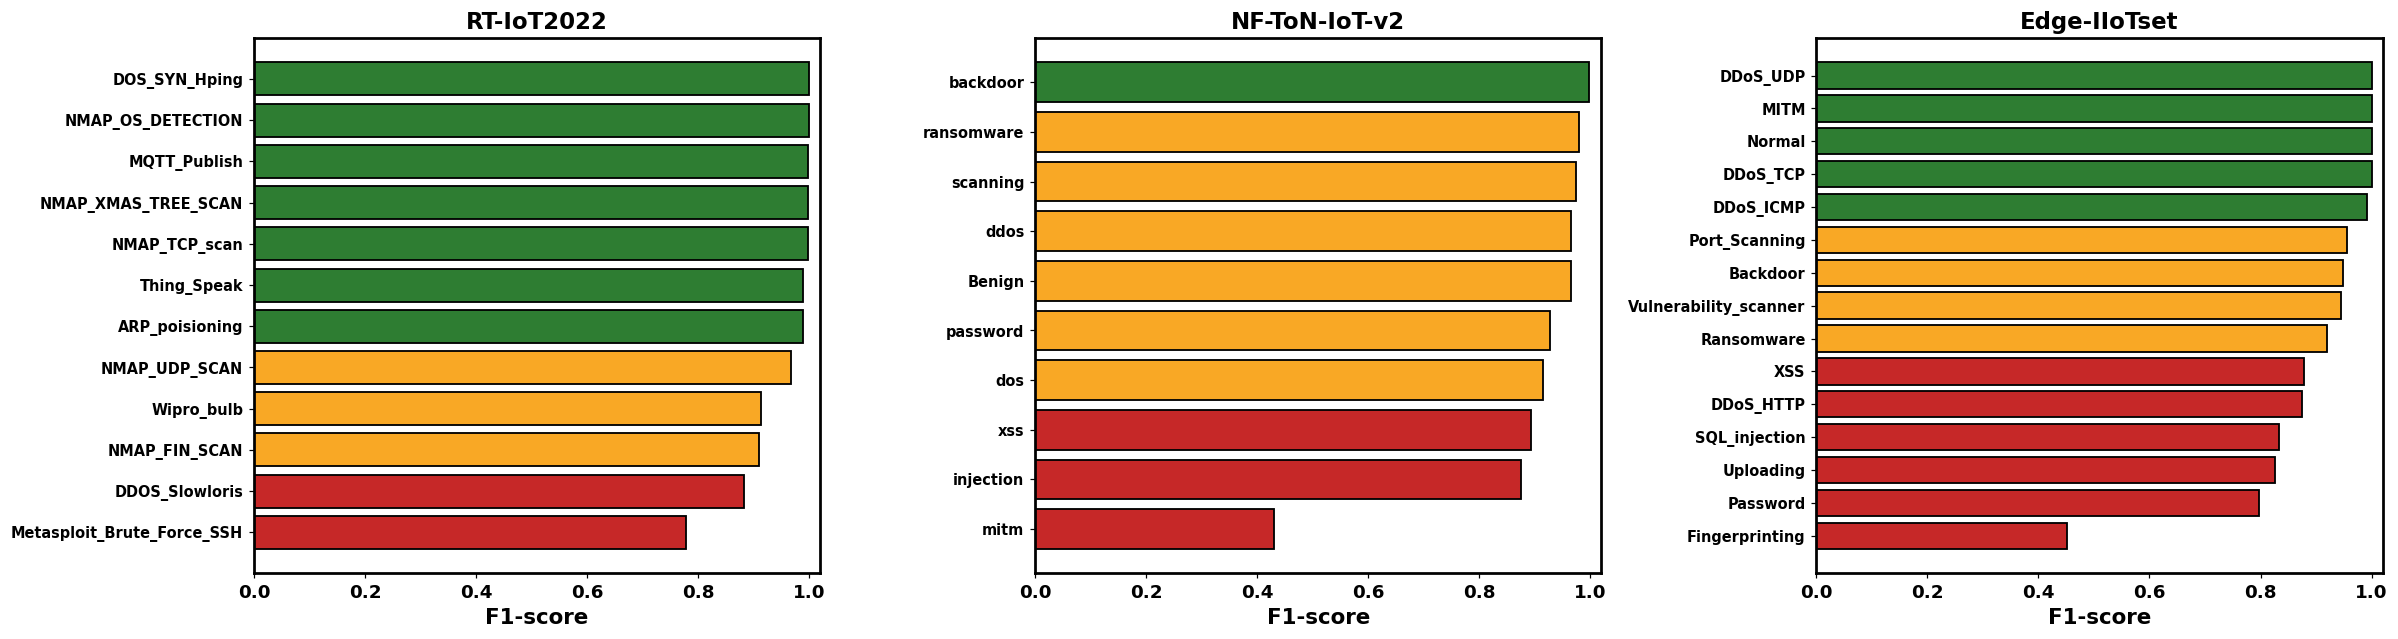

Figure 4. Per-class F1 of the neurosymbolic model, sorted ascending (fixed reference seed).
Cell 9 - Figure 3: confusion matrices | Figure 4: per-class F1 is complete


In [ ]:
# Cell 9 - Figure 3: confusion matrices | Figure 4: per-class F1 (rep seed)
# --------------------------------------------------------------------------
print('Cell 9 - Figure 3: confusion matrices | Figure 4: per-class F1')
fig, axes = plt.subplots(1, 3, figsize=(24, 7.5))
for ax, (name, d) in zip(axes, DATA.items()):
    cm = confusion_matrix(d["yte"], RESULTS_REP[name]["Neurosymbolic"]["pred"])
    cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    n = len(d["classes"]); fs = 9 if n <= 12 else 7
    for i in range(n):
        for j in range(n):
            if cmn[i, j] >= 0.01:
                ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=fs,
                        fontweight="bold", color="white" if cmn[i, j] > 0.55 else "black")
    ax.set_xticks(range(n)); ax.set_yticks(range(n))
    ax.set_xticklabels(d["classes"], rotation=90, fontsize=8.5, fontweight="bold")
    ax.set_yticklabels(d["classes"], fontsize=8.5, fontweight="bold")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    mu, sd = agg(name, "Neurosymbolic", "acc")
    ax.set_title(f"{name}  (acc={mu*100:.2f}+/-{sd*100:.2f}%)")
    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
    for t in cb.ax.get_yticklabels(): t.set_fontweight("bold")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig3_confusion_matrices.png"); plt.show()
print("Figure 3. Row-normalized confusion matrices of the neurosymbolic model (fixed reference seed).")

fig, axes = plt.subplots(1, 3, figsize=(22, 6))
for ax, (name, d) in zip(axes, DATA.items()):
    f1c = f1_score(d["yte"], RESULTS_REP[name]["Neurosymbolic"]["pred"], average=None, zero_division=0)
    order = np.argsort(f1c)
    colors = ["#C62828" if v < .90 else "#F9A825" if v < .98 else "#2E7D32" for v in f1c[order]]
    ax.barh(range(len(f1c)), f1c[order], color=colors, edgecolor="black", linewidth=1.2)
    ax.set_yticks(range(len(f1c)))
    ax.set_yticklabels([d["classes"][i] for i in order], fontsize=9.5, fontweight="bold")
    ax.set_xlim(0, 1.02); ax.set_xlabel("F1-score"); ax.set_title(name); bold_ticks(ax)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig4_perclass_f1.png"); plt.show()
print("Figure 4. Per-class F1 of the neurosymbolic model, sorted ascending (fixed reference seed).")
print('Cell 9 - Figure 3: confusion matrices | Figure 4: per-class F1 is complete')


Cell 10 - Classical + deep baselines + deployment profiling (single thread)
RT-IoT2022      OURS  BN-fold err=7.6e-06 | val acc FP32=99.68% INT8=99.64% | lat FP32=0.060 INT8=0.158 ms | INT8 eligible but not faster (0.158 vs 0.060 ms)
RT-IoT2022      OURS  deployed FP32-folded test acc=99.69%  lat=0.060 ms  size=232 KB (params*4 = 230 KB)
RT-IoT2022      RandomForest  acc= 99.82%  F1m=0.9542  lat=   5.362 ms  size=      5009 KB  fit=   5.8s
RT-IoT2022      HistGradBoost acc= 98.90%  F1m=0.7463  lat=   1.379 ms  size=       566 KB  fit=   6.0s
RT-IoT2022      DecisionTree  acc= 99.78%  F1m=0.9504  lat=   0.119 ms  size=        43 KB  fit=   1.0s
RT-IoT2022      RF-20x12      acc= 99.83%  F1m=0.9640  lat=   1.457 ms  size=       894 KB  fit=   1.2s
RT-IoT2022      LightGBM      acc= 72.28%  F1m=0.1418  lat=   0.904 ms  size=      2046 KB  fit=  12.5s
   RT-IoT2022 (TabCNN) | seed 42 | epoch  1/120  loss=1.6672  val-acc=0.8493  (2s)
   RT-IoT2022 (TabCNN) | seed 42 | epoch  5/120  loss=0.2

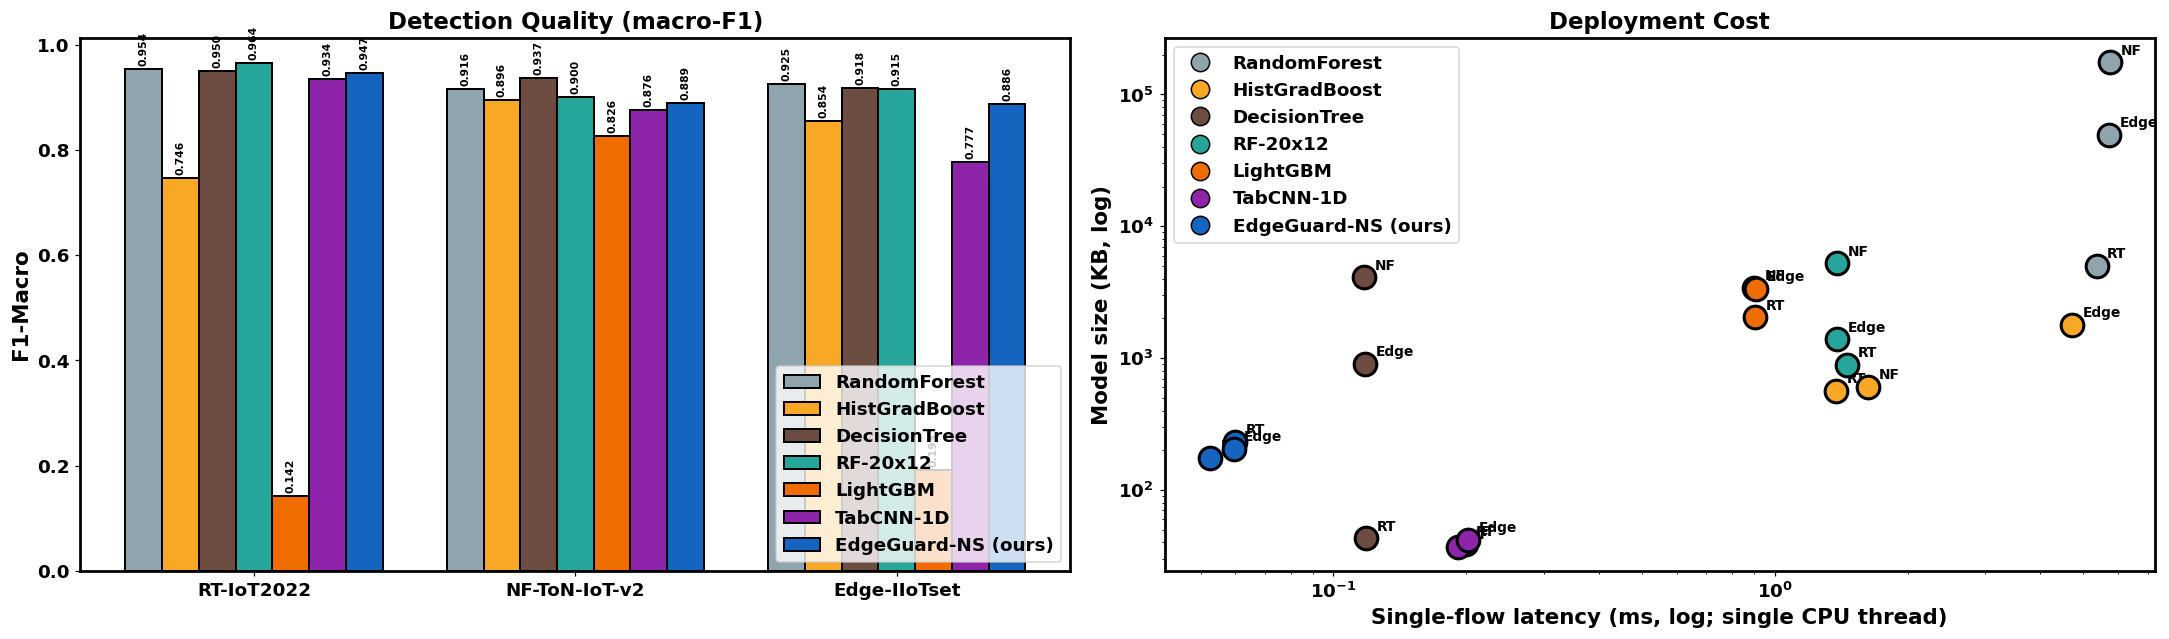

Figure 5. Detection quality (left) and deployment cost (right) versus classical and deep baselines on identical splits (latency: x86 CPU, single thread).
Cell 10 - Classical + deep baselines + deployment profiling is complete


In [ ]:
# Cell 10 - Classical + deep baselines (RF, HistGB, 1-D CNN) + deployment profiling | Figure 5
#   Identical splits; accuracy/F1 vs single-flow latency vs serialized size.
#   Latency is measured on ONE cpu thread - for our model AND every baseline
#   (threadpool_limits + n_jobs=1 at prediction time).
#   INT8 eligibility is decided on VALIDATION accuracy (held-out split); test
#   accuracy is computed only for the variant already selected.
# ---------------------------------------------------------------------------------------------
print('Cell 10 - Classical + deep baselines + deployment profiling (single thread)')
if SINGLE_THREAD_LATENCY:
    torch.set_num_threads(1)

class TabCNN(nn.Module):     # compact deep baseline: 1-D conv over the feature vector
    def __init__(self, n_in, n_out, ch=32):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv1d(1, ch, 5, padding=2), nn.BatchNorm1d(ch), nn.ReLU(),
            nn.Conv1d(ch, ch, 5, padding=2), nn.BatchNorm1d(ch), nn.ReLU(),
            nn.AdaptiveAvgPool1d(8), nn.Flatten(),
            nn.Linear(ch * 8, n_out))
    def forward(self, x): return self.body(x.unsqueeze(1))

def med_ms(fn, r=100):
    for _ in range(10): fn()
    ts = []
    for _ in range(r):
        t = time.perf_counter(); fn(); ts.append((time.perf_counter() - t) * 1e3)
    return float(np.median(ts))

def torch_runner(m, x1):
    def run1():
        with torch.no_grad(): m(x1)
    return run1

def ser_kb(m):
    buf = io.BytesIO(); torch.save(m.state_dict(), buf); return buf.getbuffer().nbytes / 1024

def profile_ours(name, model, d, seed=REP_SEED, reps=300):
    n_in, n_out = d["Xte"].shape[1], len(d["classes"])
    cpu = EdgeGuardNet(n_in, n_out)
    cpu.load_state_dict({k: v.cpu() for k, v in model.state_dict().items()}); cpu.eval()
    folded = fold_bn(cpu, n_in, n_out)
    xt = torch.tensor(d["Xte"])
    va = heldout_idx(d, seed)                         # validation rows (never trained on)
    xv, yv = torch.tensor(d["Xtr"][va]), d["ytr"][va]
    q = torch.ao.quantization.quantize_dynamic(folded, {nn.Linear}, dtype=torch.qint8)
    with torch.no_grad():
        fold_err = (cpu(xt[:2000]) - folded(xt[:2000])).abs().max().item()
        acc_fp32_val = accuracy_score(yv, folded(xv).argmax(1).numpy())
        acc_int8_val = accuracy_score(yv, q(xv).argmax(1).numpy())
    params = sum(p.numel() for p in folded.parameters())
    size_f, size_q = ser_kb(folded), ser_kb(q)       # serialized state_dict, same basis as baselines
    x1 = xt[:1]
    lat_f, lat_q = med_ms(torch_runner(folded, x1), reps), med_ms(torch_runner(q, x1), reps)
    int8_ok = (acc_fp32_val - acc_int8_val) <= 0.01   # decided on VALIDATION accuracy only
    cands = [("FP32-folded", folded, lat_f, size_f)]
    if int8_ok:
        cands.append(("INT8", q, lat_q, size_q))
    variant, dep, lat, size_kb = min(cands, key=lambda c: c[2])   # delay-sensitive: pick fastest
    if variant == "INT8":
        reason = "INT8 selected (within 1 pp on validation and faster)"
    elif not int8_ok:
        reason = f"INT8 rejected: validation drop {(acc_fp32_val - acc_int8_val)*100:.2f} pp > 1 pp"
    else:
        reason = f"INT8 eligible but not faster ({lat_q:.3f} vs {lat_f:.3f} ms)"
    with torch.no_grad():                             # test accuracy of the SELECTED variant only
        acc_dep = accuracy_score(d["yte"], dep(xt).argmax(1).numpy())
    return dict(fold_err=fold_err, acc_dep=acc_dep, acc_fp32_val=acc_fp32_val,
                acc_int8_val=acc_int8_val, variant=variant, reason=reason,
                lat=lat, lat_fp32=lat_f, lat_int8=lat_q, params=params,
                size_kb=size_kb, size_fp32=size_f, size_int8=size_q,
                size_param_kb=params * 4 / 1024)

BASELINES = {
 "RandomForest":   lambda seed: RandomForestClassifier(n_estimators=100, min_samples_leaf=5,
                                                       n_jobs=-1, random_state=seed),
 "HistGradBoost":  lambda seed: HistGradientBoostingClassifier(random_state=seed),
 # lightweight tree baselines (reviewer 2)
 "DecisionTree":   lambda seed: DecisionTreeClassifier(min_samples_leaf=5, random_state=seed),
 "RF-20x12":       lambda seed: RandomForestClassifier(n_estimators=20, max_depth=12, min_samples_leaf=5,
                                                       n_jobs=-1, random_state=seed),
}
# LightGBM removed: with default settings it failed to train on RT-IoT2022 and Edge-IIoTset
# (72% / 32% accuracy); HistGradBoost is the gradient-boosting baseline.
PROF, BASE_RES = {}, []
for name, d in DATA.items():
    PROF[name] = p = profile_ours(name, MODELS[name], d)
    print(f"{name:15s} OURS  BN-fold err={p['fold_err']:.1e} | val acc FP32={p['acc_fp32_val']*100:.2f}% "
          f"INT8={p['acc_int8_val']*100:.2f}% | lat FP32={p['lat_fp32']:.3f} INT8={p['lat_int8']:.3f} ms "
          f"| {p['reason']}", flush=True)
    print(f"{name:15s} OURS  deployed {p['variant']} test acc={p['acc_dep']*100:.2f}%  "
          f"lat={p['lat']:.3f} ms  size={p['size_kb']:.0f} KB (params*4 = {p['size_param_kb']:.0f} KB)",
          flush=True)
    # classical baselines
    for bname, ctor in BASELINES.items():
        t0 = time.time(); clf = ctor(REP_SEED).fit(d["Xtr"], d["ytr"]); t_fit = time.time() - t0
        pred = clf.predict(d["Xte"])
        x1 = d["Xte"][:1]
        if "n_jobs" in clf.get_params():
            clf.set_params(n_jobs=1)                      # one thread at prediction time
        with threadpool_limits(limits=1):
            lat = med_ms(lambda: clf.predict(x1), 50)
        size_kb = len(pickle.dumps(clf)) / 1024
        row = dict(Dataset=name, Model=bname, acc=accuracy_score(d["yte"], pred),
                   f1_m=f1_score(d["yte"], pred, average="macro", zero_division=0),
                   lat_ms=lat, size_kb=size_kb, fit_s=t_fit)
        BASE_RES.append(row)
        print(f"{name:15s} {bname:13s} acc={row['acc']*100:6.2f}%  F1m={row['f1_m']:.4f}  "
              f"lat={lat:8.3f} ms  size={size_kb:10.0f} KB  fit={t_fit:6.1f}s", flush=True)
    # deep baseline: 1-D CNN trained under the IDENTICAL loop and split
    cnn, _, _, _, t_fit = train_model(d, name + " (TabCNN)", REP_SEED, ctor=TabCNN)
    cnn_cpu = TabCNN(d["Xte"].shape[1], len(d["classes"]))
    cnn_cpu.load_state_dict({k: v.cpu() for k, v in cnn.state_dict().items()}); cnn_cpu.eval()
    xt = torch.tensor(d["Xte"])
    with torch.no_grad():
        pred = cnn_cpu(xt).argmax(1).numpy()
    buf = io.BytesIO(); torch.save(cnn_cpu.state_dict(), buf)
    lat = med_ms(torch_runner(cnn_cpu, xt[:1]), 200)
    row = dict(Dataset=name, Model="TabCNN-1D", acc=accuracy_score(d["yte"], pred),
               f1_m=f1_score(d["yte"], pred, average="macro", zero_division=0),
               lat_ms=lat, size_kb=buf.getbuffer().nbytes / 1024, fit_s=t_fit)
    BASE_RES.append(row)
    print(f"{name:15s} {'TabCNN-1D':13s} acc={row['acc']*100:6.2f}%  F1m={row['f1_m']:.4f}  "
          f"lat={lat:8.3f} ms  size={row['size_kb']:10.0f} KB  fit={t_fit:6.1f}s", flush=True)
    del cnn
    mu_a, _ = agg(name, "Neurosymbolic", "acc"); mu_f, _ = agg(name, "Neurosymbolic", "f1_m")
    BASE_RES.append(dict(Dataset=name, Model="EdgeGuard-NS (ours)", acc=mu_a, f1_m=mu_f,
                         lat_ms=p["lat"], size_kb=p["size_kb"], fit_s=np.nan))
BASE_DF = pd.DataFrame(BASE_RES)
BASE_DF.to_csv("baseline_comparison.csv", index=False)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(20, 6))
mcolor = {"RandomForest": "#90A4AE", "HistGradBoost": "#F9A825", "DecisionTree": "#6D4C41",
          "RF-20x12": "#26A69A",
          "TabCNN-1D": "#8E24AA", "EdgeGuard-NS (ours)": "#1565C0"}
mcolor = {m: c for m, c in mcolor.items() if m in set(BASE_DF.Model)}
xx = np.arange(len(DATA)); wdt = 0.8 / len(mcolor)
for k, mdl in enumerate(mcolor):
    v = [BASE_DF[(BASE_DF.Dataset == n) & (BASE_DF.Model == mdl)].f1_m.iloc[0] for n in DATA]
    b = a1.bar(xx + (k - (len(mcolor) - 1) / 2) * wdt, v, wdt, label=mdl, color=mcolor[mdl],
               edgecolor="black", linewidth=1.3)
    a1.bar_label(b, fmt="%.3f", fontweight="bold", fontsize=7, padding=2, rotation=90)
a1.set_xticks(xx); a1.set_xticklabels(DATA.keys(), fontweight="bold")
a1.set_ylabel("F1-Macro"); a1.set_title("Detection Quality (macro-F1)")
a1.legend(prop={"weight": "bold"}, loc="lower right"); bold_ticks(a1)
for _, r in BASE_DF.iterrows():
    a2.scatter(r.lat_ms, r.size_kb, s=220, color=mcolor[r.Model],
               edgecolor="black", linewidth=2, zorder=3)
    a2.annotate(r.Dataset.split("-")[0], (r.lat_ms, r.size_kb), xytext=(7, 5),
                textcoords="offset points", fontsize=9, fontweight="bold")
a2.set_xscale("log"); a2.set_yscale("log")
a2.set_xlabel("Single-flow latency (ms, log; single CPU thread)"); a2.set_ylabel("Model size (KB, log)")
a2.set_title("Deployment Cost")
handles = [plt.Line2D([0], [0], marker="o", linestyle="", markersize=12, color=c,
                      markeredgecolor="black", label=m) for m, c in mcolor.items()]
a2.legend(handles=handles, prop={"weight": "bold"}); bold_ticks(a2)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig5_baseline_comparison.png"); plt.show()
print("Figure 5. Detection quality (left) and deployment cost (right) versus classical and deep "
      "baselines on identical splits (latency: x86 CPU, single thread).")
print('Cell 10 - Classical + deep baselines + deployment profiling is complete')


Cell 11 - Zero-day (open-set) experiment: negative controls + OOD baselines
   RT-IoT2022 | seed 42 | epoch  1/120  loss=0.7259  val-acc=0.9721  (0s)
   RT-IoT2022 | seed 42 | epoch  5/120  loss=0.1063  val-acc=0.9915  (0s)
   RT-IoT2022 | seed 42 | epoch 10/120  loss=0.0652  val-acc=0.9945  (0s)
   RT-IoT2022 | seed 42 | epoch 15/120  loss=0.0577  val-acc=0.9915  (1s)
   RT-IoT2022 | seed 42 | epoch 20/120  loss=0.0507  val-acc=0.9950  (1s)
   RT-IoT2022 | seed 42 | epoch 25/120  loss=0.0431  val-acc=0.9959  (1s)
   RT-IoT2022 | seed 42 | epoch 30/120  loss=0.0392  val-acc=0.9966  (1s)
   RT-IoT2022 | seed 42 | epoch 35/120  loss=0.0390  val-acc=0.9963  (2s)
   RT-IoT2022 | seed 42 | epoch 40/120  loss=0.0355  val-acc=0.9964  (2s)
   RT-IoT2022 | seed 42 | epoch 45/120  loss=0.0338  val-acc=0.9971  (2s)
   RT-IoT2022 | seed 42 | epoch 50/120  loss=0.0316  val-acc=0.9971  (2s)
   RT-IoT2022 | seed 42 | epoch 55/120  loss=0.0306  val-acc=0.9972  (3s)
   RT-IoT2022 | seed 42 | epoch 60/1

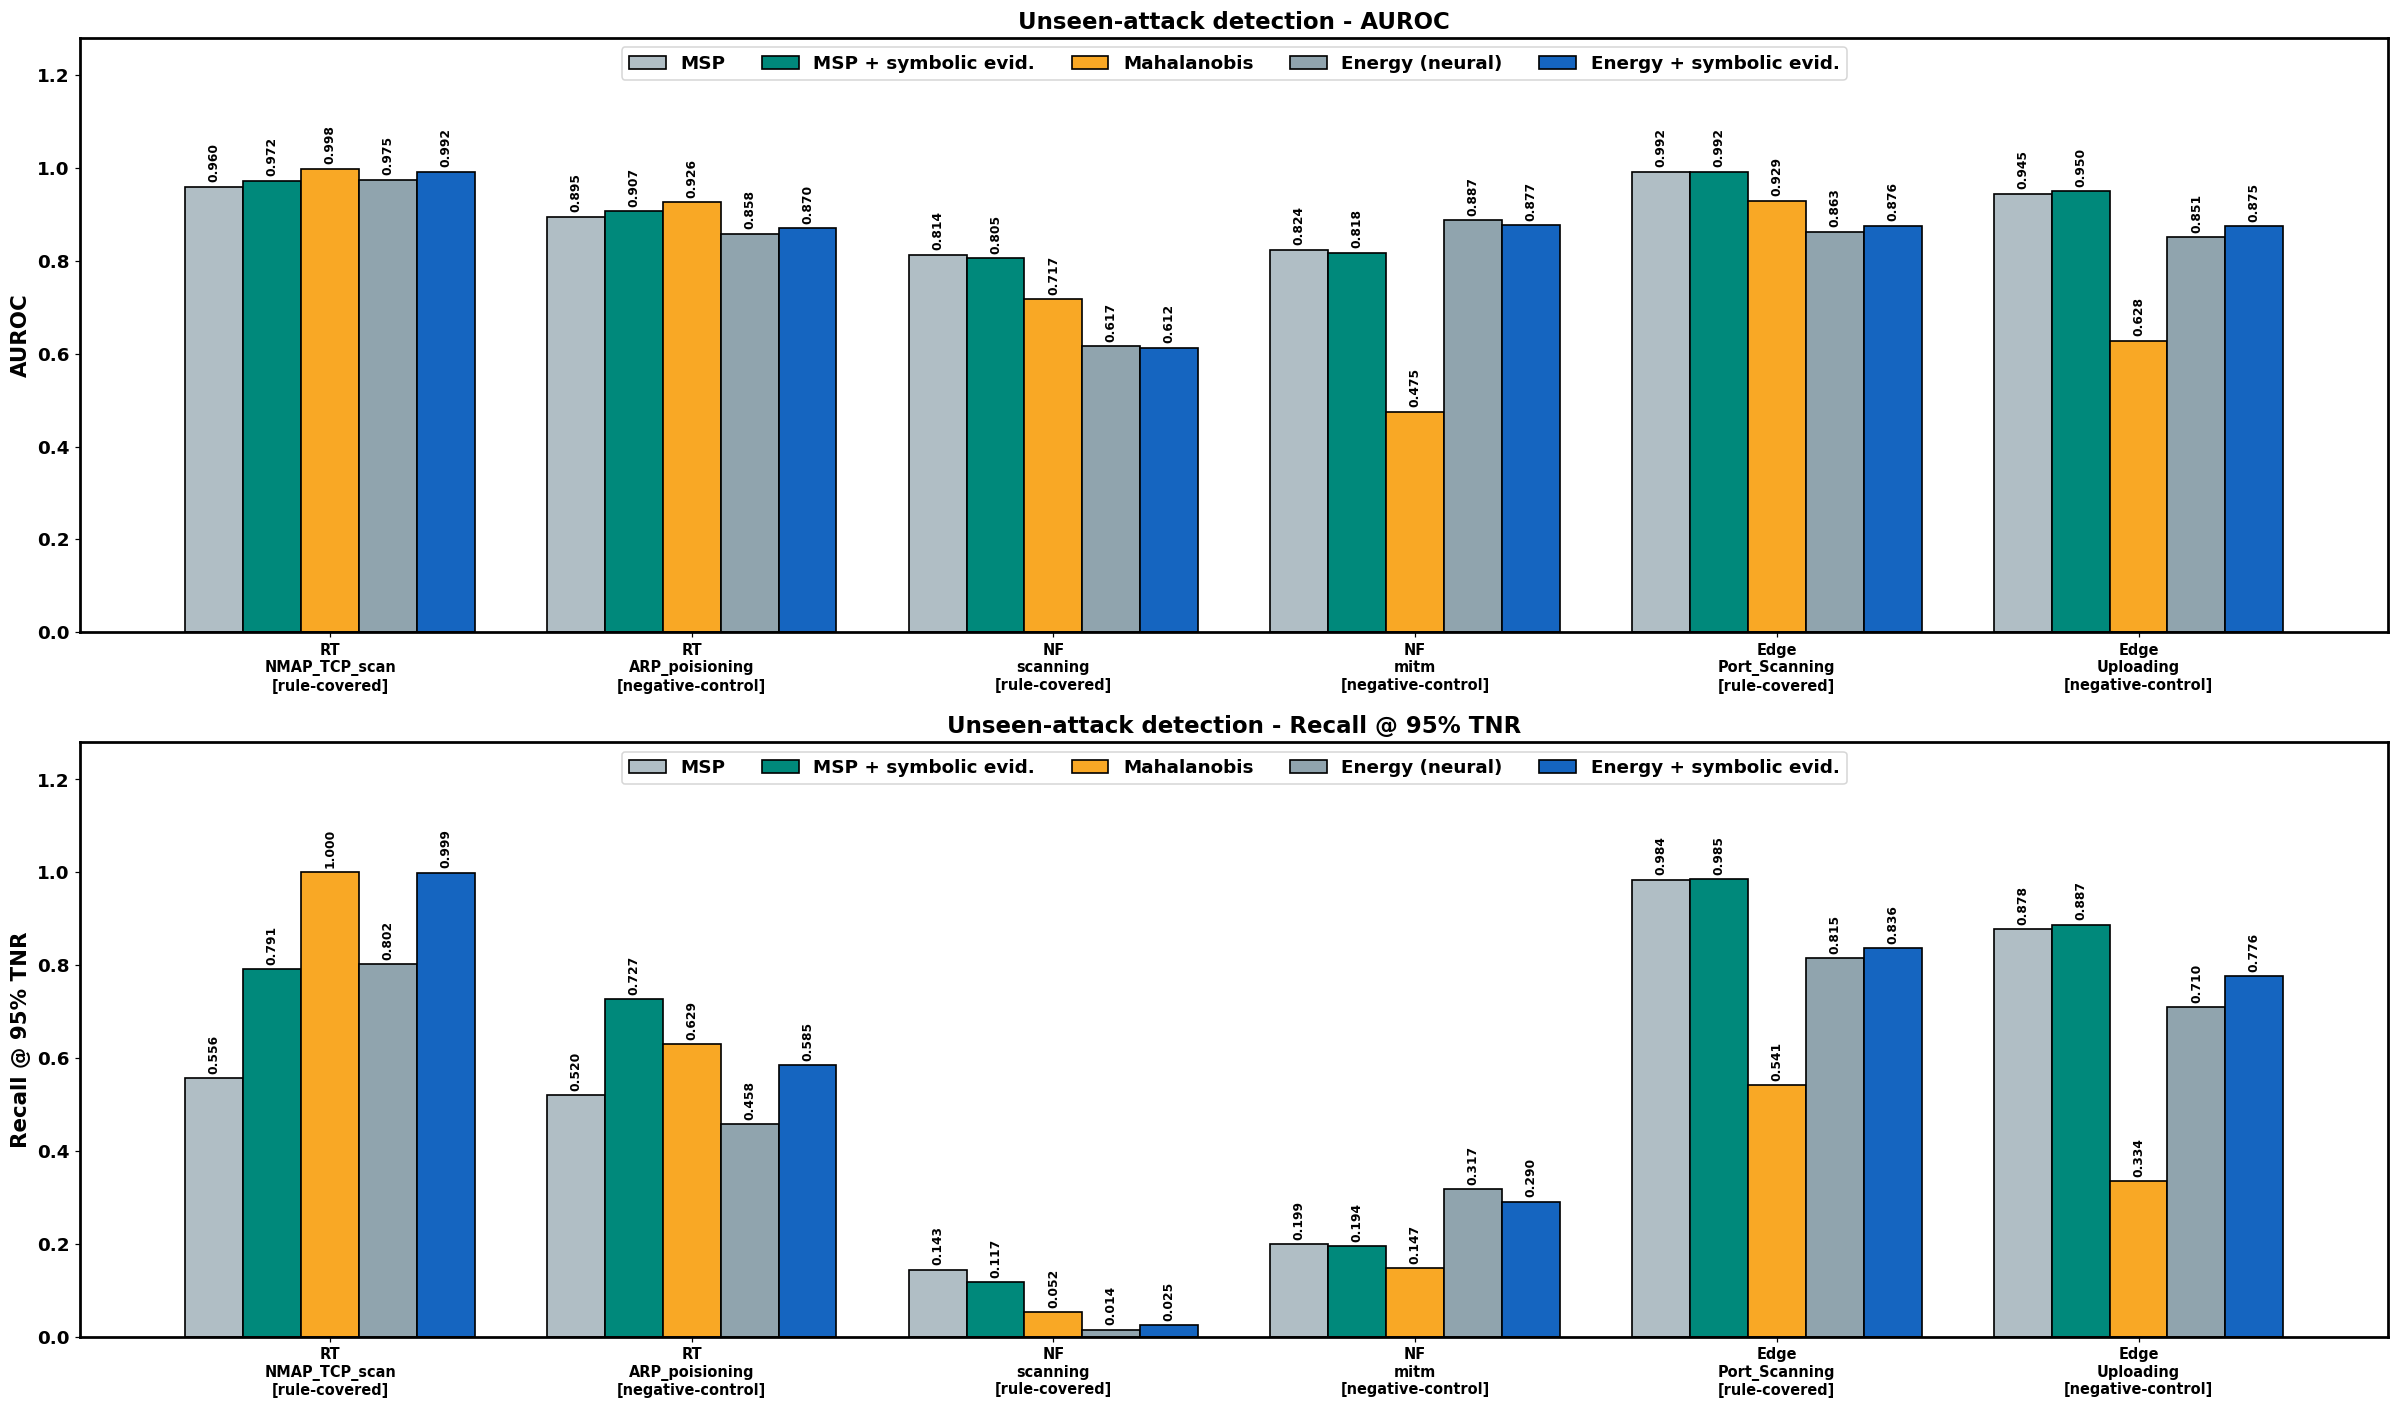

Figure 6. Zero-day detection of withheld attack families: benign-rarity symbolic evidence as an additive channel on MSP and energy scores, vs Mahalanobis, under identical models and splits (bars show mean over seeds; per-seed values and the ODIN baseline in zero_day_results.csv).
Cell 11 - Zero-day (open-set) experiment with negative controls + OOD baselines is complete


In [ ]:
# Cell 11 - Zero-day (open-set) experiment: negative controls + OOD baselines
#   Symbolic evidence = PRIOR KNOWLEDGE, deliberately NOT calibrated on known
#   attacks: each rule's weight is its benign rarity,
#       v_r = (1 - p_benign_r)  if p_benign_r <= 10%,  else 0
#   (a rule benign traffic rarely fires is valid anomaly evidence even if no
#   KNOWN attack fires it). The symbolic term s(x) = (A(x) @ v) / sum(v) is
#   BOUNDED in [0,1], so validation-calibrated thresholds transfer stably.
#   Symbolic evidence is an ADDITIVE channel on top of ANY base OOD score:
#   reported as MSP vs MSP+sym and Energy vs Energy+sym (identical models).
#   lambda per base is DOUBLE-GUARDED do-no-harm calibrated: the largest grid
#   value that degrades NEITHER validation AUROC NOR validation recall at the
#   95%-TNR operating point (known attacks vs benign). The second guard
#   protects the DEPLOYED THRESHOLD: a large lambda lets rule-firing benign
#   flows inflate the 95th-percentile threshold, silently crushing recall at
#   test time even while AUROC (threshold-free) looks fine - that failure now
#   shows up on validation and the offending lambda is rejected.
#   Negative-control validity: a control's WEIGHTED activation (mean s over its
#   flows) must stay below 5%; raw per-rule rates are printed alongside.
#   Thresholds (R@95TNR) come from VALIDATION benign scores; realized test TNR
#   is recorded as a sanity check.
# --------------------------------------------------------------------------------
print('Cell 11 - Zero-day (open-set) experiment: negative controls + OOD baselines')
HOLDOUTS = {"RT-IoT2022":   [("NMAP_TCP_scan", "rule-covered"), ("ARP_poisioning", "negative-control")],
            "NF-ToN-IoT-v2":[("scanning",      "rule-covered"), ("mitm",           "negative-control")],
            "Edge-IIoTset": [("Port_Scanning", "rule-covered"), ("Uploading",      "negative-control")]}
HOLDOUTS_ALT = {"RT-IoT2022":    ["Metasploit_Brute_Force_SSH", "DDOS_Slowloris"],
                "NF-ToN-IoT-v2": ["injection", "ransomware", "backdoor", "password"],
                "Edge-IIoTset":  ["SQL_injection", "XSS", "Ransomware", "MITM"]}
LAMBDA_GRID  = [0.0, 0.5, 1.0, 2.0]
LAM_TOL      = 0.002       # do-no-harm tolerance on validation AUROC and recall
BEN_RATE_MAX = 0.10        # rules benign fires on >10% of flows carry no evidence
MAHA_FIT_MAX = 100_000

def energy(lg): return -np.log(np.exp(lg - lg.max(1, keepdims=True)).sum(1) + 1e-12) - lg.max(1)

def penult_feats(model, X, bs=8192):
    # penultimate-layer activations (input to the final Linear)
    outs = []
    model.eval()
    with torch.no_grad():
        for i in range(0, len(X), bs):
            xb = torch.tensor(X[i:i+bs], device=DEVICE)
            outs.append(model.net[:-1](xb).cpu().numpy())
    return np.concatenate(outs).astype(np.float64)

def fit_mahalanobis(feats, y, n_classes):
    # class-conditional Gaussians with tied covariance
    mu_all = feats.mean(0)
    means = np.stack([feats[y == c].mean(0) if (y == c).any() else mu_all
                      for c in range(n_classes)])
    Xc = feats - means[y]
    cov = Xc.T @ Xc / len(Xc) + 1e-6 * np.eye(feats.shape[1])
    return means, np.linalg.inv(cov)

def maha_score(feats, means, prec, bs=20_000):
    # min over classes of squared Mahalanobis distance (higher = more OOD)
    out = np.empty(len(feats))
    for i in range(0, len(feats), bs):
        f = feats[i:i+bs]
        d = np.stack([np.einsum('ij,jk,ik->i', f - mu, prec, f - mu) for mu in means])
        out[i:i+bs] = d.min(0)
    return out

def _std(x, mu, sd): return (x - mu) / sd

def pick_lam(zb_v, s_v, ben_v, recall_guard=True):
    # largest lambda that degrades NEITHER validation AUROC NOR validation
    # recall at the 95%-TNR operating point (both on known attacks vs benign);
    # guards the deployed threshold, not just the ranking metric.
    # recall_guard=False -> AUROC guard only (ablation)
    y_att = ~ben_v
    base_auc = roc_auc_score(y_att, zb_v)
    base_rec = (zb_v[y_att] > np.percentile(zb_v[ben_v], 95)).mean()
    ok = [0.0]
    for L in LAMBDA_GRID[1:]:
        sc  = zb_v + L * s_v
        rec = (sc[y_att] > np.percentile(sc[ben_v], 95)).mean()
        if (roc_auc_score(y_att, sc) >= base_auc - LAM_TOL
                and (not recall_guard or rec >= base_rec - LAM_TOL)):
            ok.append(L)
    return max(ok)

ZD = []
for name, df in DATASETS.items():
    present = set(df[LABEL_COL[name]].astype(str))
    for hold, kind in HOLDOUTS[name]:
        if hold not in present:
            print(f"{name}: holdout class '{hold}' not found - skipping "
                  f"(alternates: {HOLDOUTS_ALT.get(name, [])})"); continue
        for seed in ZD_SEEDS:
            d = preprocess_openset(df, LABEL_COL[name], DROP_COLS[name], seed, hold)
            model, _, _, n_ep, t_s = train_model(d, name, seed)
            eng = SymbolicRuleEngine(name, d["raw_train"], LABEL_COL[name])
            model.eval()
            groups = np.array([class_to_group(c) for c in d["classes"]])

            # ---- validation sample: KNOWN data only (no holdout access) ----
            # CAL_ON_HELDOUT: the early-stopping split, never used for gradient steps
            if CAL_ON_HELDOUT:
                sel = np.random.RandomState(seed + 1).permutation(heldout_idx(d, seed))[:20_000]
            else:
                n = len(d["ytr"]); m = min(n, 20_000, max(2_000, n // 10))
                sel = np.random.RandomState(seed + 1).choice(n, size=m, replace=False)
            with torch.no_grad():
                lg_v = model(torch.tensor(d["Xtr"][sel], device=DEVICE)).cpu().numpy()
            A_v   = eng.activations(d["raw_train"].iloc[sel])
            ben_v = groups[d["ytr"][sel]] == "BENIGN"
            if ben_v.sum() < 50 or (~ben_v).sum() < 50:
                print(f"   {name}/{hold} seed={seed}: sparse val classes - skipping"); continue

            # benign-rarity evidence weights (prior knowledge, bounded s)
            p_b = A_v[ben_v].mean(0)
            v   = np.where(p_b <= BEN_RATE_MAX, 1.0 - p_b, 0.0)
            vs  = max(v.sum(), 1e-9)
            s_v = (A_v @ v) / vs                          # in [0, 1]
            u   = np.ones_like(v); us = u.sum()           # ablation: uniform rule weights
            su_v = (A_v @ u) / us

            # base OOD scores, z-scored on validation benign
            e_v, msp_v = energy(lg_v), 1.0 - softmax_np(lg_v).max(1)
            odin_v     = 1.0 - softmax_np(lg_v / 1000.0).max(1)
            fit_i = np.random.RandomState(seed + 2).choice(
                        len(d["Xtr"]), min(len(d["Xtr"]), MAHA_FIT_MAX), replace=False)
            means, prec = fit_mahalanobis(penult_feats(model, d["Xtr"][fit_i]),
                                          d["ytr"][fit_i], len(d["classes"]))
            mah_v = maha_score(penult_feats(model, d["Xtr"][sel]), means, prec)
            cal = {}                                       # per-base (mu, sd) on val benign
            for bn, bv in [("Energy", e_v), ("MSP", msp_v), ("ODIN", odin_v), ("Maha", mah_v)]:
                cal[bn] = (bv[ben_v].mean(), bv[ben_v].std() + 1e-9)
            ze_v, zm_v = _std(e_v, *cal["Energy"]), _std(msp_v, *cal["MSP"])
            lam_e = pick_lam(ze_v, s_v, ben_v)
            lam_m = pick_lam(zm_v, s_v, ben_v)
            lam_mu = pick_lam(zm_v, su_v, ben_v)                      # ablation: uniform v
            lam_ma = pick_lam(zm_v, s_v, ben_v, recall_guard=False)   # ablation: AUROC guard only

            # final scoring on test benign vs the never-seen family
            with torch.no_grad():
                lg_te = model(torch.tensor(d["Xte"],   device=DEVICE)).cpu().numpy()
                lg_h  = model(torch.tensor(d["Xhold"], device=DEVICE)).cpu().numpy()
            ben_te = groups[d["yte"]] == "BENIGN"
            if ben_te.sum() < 50:
                print(f"{name}/{hold}: too few benign test flows - skipping"); break
            A_te, A_h = eng.activations(d["raw_test"]), eng.activations(d["raw_hold"])
            s_te, s_h = (A_te @ v) / vs, (A_h @ v) / vs
            su_te, su_h = (A_te @ u) / us, (A_h @ u) / us

            # negative-control validity: WEIGHTED activation of the holdout
            act_h = A_h.mean(0); wact = float(s_h.mean())
            diag  = "; ".join(f"{rn}={a:.3f}" for rn, a in zip(eng.rule_names, act_h))
            flag  = (kind == "negative-control" and wact > CONTROL_ACT_MAX)
            print(f"   [{name}/{hold}] holdout rule rates: {diag} | weighted={wact:.4f}"
                  + ("  << WARNING: control carries weighted evidence >5% - NOT a "
                     "valid negative control; substitute from HOLDOUTS_ALT" if flag else ""))

            f_te, f_h = penult_feats(model, d["Xte"]), penult_feats(model, d["Xhold"])
            e_te, e_h   = _std(energy(lg_te), *cal["Energy"]), _std(energy(lg_h), *cal["Energy"])
            m_te, m_h   = (_std(1 - softmax_np(lg_te).max(1), *cal["MSP"]),
                           _std(1 - softmax_np(lg_h ).max(1), *cal["MSP"]))
            o_te, o_h = (_std(1 - softmax_np(lg_te/1000.).max(1), *cal["ODIN"]),
                         _std(1 - softmax_np(lg_h /1000.).max(1), *cal["ODIN"]))
            k_te, k_h = (_std(maha_score(f_te, means, prec), *cal["Maha"]),
                         _std(maha_score(f_h,  means, prec), *cal["Maha"]))
            o_v, k_v  = _std(odin_v, *cal["ODIN"]), _std(mah_v, *cal["Maha"])
            # combined unsupervised detector: Isolation Forest on the stacked
            # benign-standardised scores, fitted on validation BENIGN flows only
            Z = lambda *c: np.column_stack(c)
            iso = IsolationForest(n_estimators=200, random_state=seed).fit(
                      Z(zm_v, ze_v, o_v, k_v, s_v)[ben_v])
            iso_sc = lambda M: -iso.score_samples(M)
            methods = {
                "MSP":                     (m_te, m_h, zm_v),
                "MSP + symbolic evid.":    (m_te + lam_m * s_te, m_h + lam_m * s_h,
                                            zm_v + lam_m * s_v),
                "ODIN (T=1000)":           (o_te, o_h, o_v),
                "Mahalanobis":             (k_te, k_h, k_v),
                "Energy (neural)":         (e_te, e_h, ze_v),
                "Energy + symbolic evid.": (e_te + lam_e * s_te, e_h + lam_e * s_h,
                                            ze_v + lam_e * s_v),
                "Combined (IsoForest)":    (iso_sc(Z(m_te, e_te, o_te, k_te, s_te)),
                                            iso_sc(Z(m_h,  e_h,  o_h,  k_h,  s_h)),
                                            iso_sc(Z(zm_v, ze_v, o_v,  k_v,  s_v))),
            }
            if RUN_ABLATION:
                methods["MSP + evid. [uniform v]"]    = (m_te + lam_mu * su_te, m_h + lam_mu * su_h,
                                                         zm_v + lam_mu * su_v)
                methods["MSP + evid. [AUROC guard]"]  = (m_te + lam_ma * s_te, m_h + lam_ma * s_h,
                                                         zm_v + lam_ma * s_v)
            rec = {}
            for tag, (sc_te, sc_h, sc_val) in methods.items():
                sc_b  = sc_te[ben_te]
                y_bin = np.r_[np.zeros(len(sc_b)), np.ones(len(sc_h))]
                thr   = np.percentile(sc_val[ben_v], 95)   # VALIDATION-calibrated 95% TNR point
                rec[tag] = dict(auroc=roc_auc_score(y_bin, np.r_[sc_b, sc_h]),
                                rec95=float((sc_h > thr).mean()),
                                tnr=float((sc_b <= thr).mean()))   # realized test TNR (sanity)
            ev_str = "; ".join(f"{rn}={vv:+.3f}" for rn, vv in zip(eng.rule_names, v))
            ZD.append(dict(Dataset=name, Holdout=hold, Kind=kind, Seed=seed,
                           LambdaE=lam_e, LambdaM=lam_m, LambdaM_uniform=lam_mu, LambdaM_aurocguard=lam_ma,
                           CalRows=len(sel), CalBenign=int(ben_v.sum()), EvidenceWeights=ev_str,
                           WeightedActivation=wact, ControlValid=not flag,
                           **{f"{t} AUROC":   rec[t]["auroc"] for t in rec},
                           **{f"{t} R@95TNR": rec[t]["rec95"] for t in rec},
                           **{f"{t} realTNR": rec[t]["tnr"]   for t in rec}))
            print(f"{name:15s} holdout={hold:15s} [{kind}] seed={seed} "
                  f"lamE={lam_e:.1f} lamM={lam_m:.1f} v=[{ev_str}]\n    "
                  + " | ".join(f"{t}: AUROC={rec[t]['auroc']:.4f} R@95TNR={rec[t]['rec95']:.4f}"
                               for t in rec), flush=True)
            del d, model, f_te, f_h

ZD_DF = pd.DataFrame(ZD)
ZD_DF.to_csv("zero_day_results.csv", index=False)
TAGS = ["MSP", "MSP + symbolic evid.", "Mahalanobis", "Energy (neural)", "Energy + symbolic evid."]
TCOL = {"MSP": "#B0BEC5", "MSP + symbolic evid.": "#00897B", "Mahalanobis": "#F9A825",
        "Energy (neural)": "#90A4AE", "Energy + symbolic evid.": "#1565C0"}
if len(ZD_DF):
    cases = ZD_DF[["Dataset", "Holdout", "Kind"]].drop_duplicates().values.tolist()
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(22, 13))
    xx = np.arange(len(cases)); wdt = 0.16
    for ax, key, lab in [(a1, "AUROC", "AUROC"), (a2, "R@95TNR", "Recall @ 95% TNR")]:
        for k, tag in enumerate(TAGS):
            col = f"{tag} {key}"
            mu = [ZD_DF[(ZD_DF.Dataset == ds) & (ZD_DF.Holdout == h)][col].mean() for ds, h, _ in cases]
            b = ax.bar(xx + (k - 2) * wdt, mu, wdt, label=tag,
                       color=TCOL[tag], edgecolor="black", linewidth=1.1)
            ax.bar_label(b, fmt="%.3f", fontweight="bold", fontsize=8,
                         rotation=90, padding=3)
        ax.set_xticks(xx)
        ax.set_xticklabels([f"{ds.split('-')[0]}\n{h}\n[{kd}]" for ds, h, kd in cases],
                           fontweight="bold", fontsize=9.5)
        ax.set_ylabel(lab); ax.set_title(f"Unseen-attack detection - {lab}")
        ax.set_ylim(0, 1.28); ax.legend(prop={"weight": "bold"}, ncols=5, loc="upper center")
        bold_ticks(ax)
    fig.tight_layout(); fig.savefig(FIG_DIR / "fig6_zero_day.png"); plt.show()
print("Figure 6. Zero-day detection of withheld attack families: benign-rarity symbolic "
      "evidence as an additive channel on MSP and energy scores, vs Mahalanobis, under "
      "identical models and splits (bars show mean over seeds; per-seed values and the "
      "ODIN baseline in zero_day_results.csv).")
print('Cell 11 - Zero-day (open-set) experiment with negative controls + OOD baselines is complete')

Cell 11b - Figure 6b: coverage dose-response


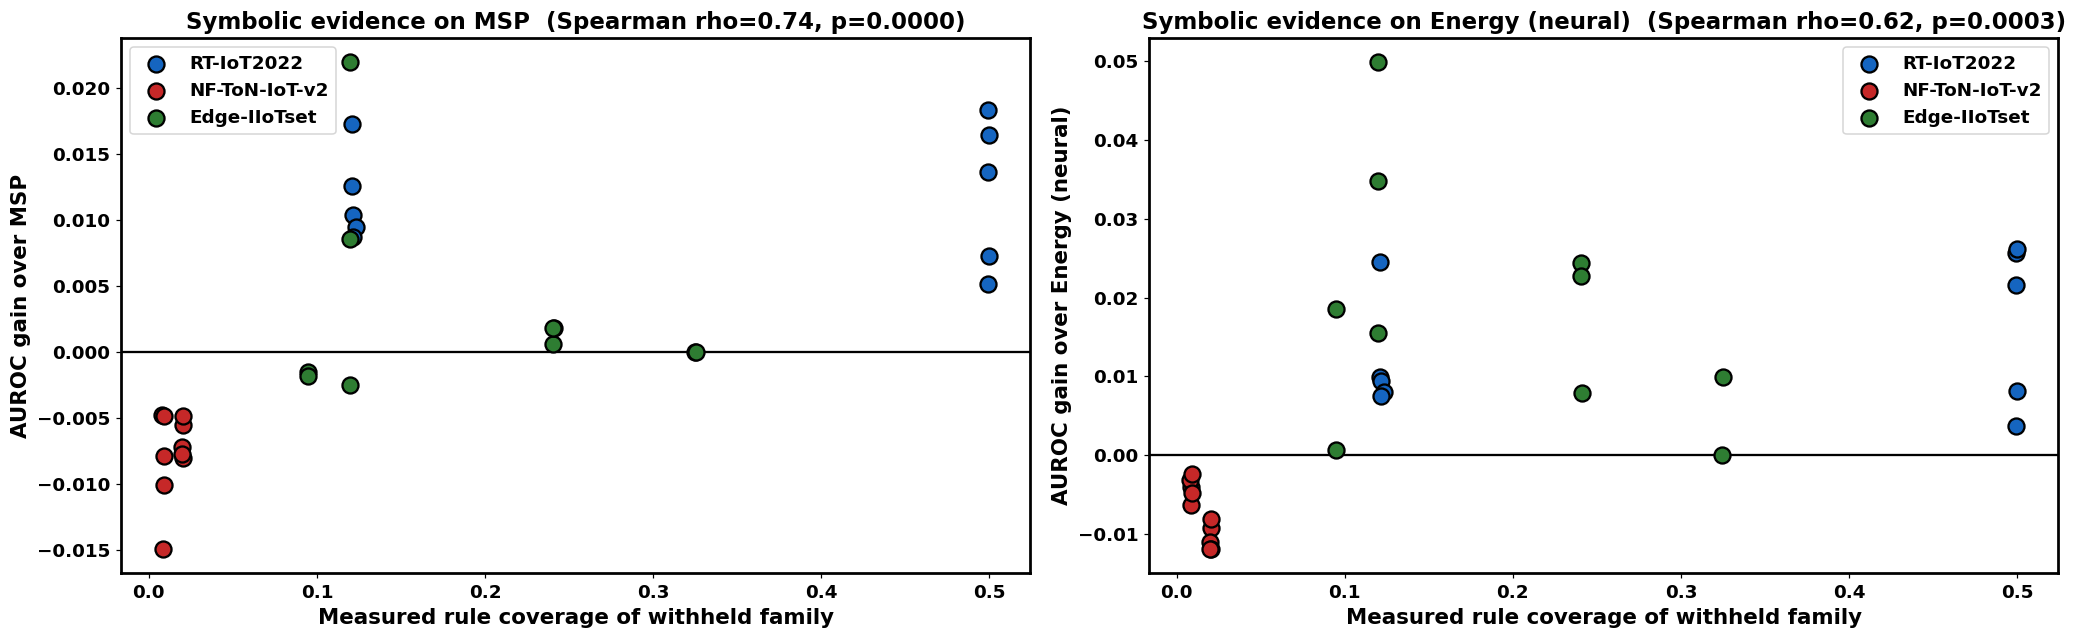

                              WeightedActivation  gain_msp  gain_en
Dataset       Holdout                                              
Edge-IIoTset  Port_Scanning               0.2744    0.0009   0.0130
              Uploading                   0.1097    0.0049   0.0239
NF-ToN-IoT-v2 mitm                        0.0203   -0.0066  -0.0104
              scanning                    0.0086   -0.0085  -0.0042
RT-IoT2022    ARP_poisioning              0.1217    0.0117   0.0119
              NMAP_TCP_scan               0.4994    0.0122   0.0170
MSP    holdout-level rho=0.829  exact p(one-sided)=0.0292  p(two-sided)=0.0583  family-bootstrap 95% CI [0.00, 1.00]  | 30-run rho=0.739 (descriptive only)
Energy holdout-level rho=0.600  exact p(one-sided)=0.1208  p(two-sided)=0.2417  family-bootstrap 95% CI [-0.50, 1.00]  | 30-run rho=0.620 (descriptive only)
Figure 6b. AUROC gain from the symbolic evidence channel versus measured rule coverage of the withheld attack family (30 runs; gain emerges wit

In [ ]:
# Cell 11b - Figure 6b: coverage dose-response of the symbolic evidence channel
#   Each point = one (dataset, holdout, seed) run. x = measured weighted rule
#   coverage of the withheld family; y = AUROC gain from adding symbolic
#   evidence to the base score. The a-priori covered/control dichotomy is
#   replaced by measured coverage: benefit appears when and only when the
#   unseen family exhibits the rule-encoded behaviors.
print('Cell 11b - Figure 6b: coverage dose-response')
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
DCOL = {"RT-IoT2022": "#1565C0", "NF-ToN-IoT-v2": "#C62828", "Edge-IIoTset": "#2E7D32"}
fig, axes = plt.subplots(1, 2, figsize=(19, 6))
for ax, base, tag in [(axes[0], "MSP", "MSP + symbolic evid."),
                      (axes[1], "Energy (neural)", "Energy + symbolic evid.")]:
    cov  = ZD_DF["WeightedActivation"].values
    gain = (ZD_DF[f"{tag} AUROC"] - ZD_DF[f"{base} AUROC"]).values
    for ds in DCOL:
        m = (ZD_DF.Dataset == ds).values
        ax.scatter(cov[m], gain[m], s=110, color=DCOL[ds], edgecolor="black",
                   linewidth=1.5, label=ds, zorder=3)
    rho, p = spearmanr(cov, gain)
    ax.axhline(0, color="black", linewidth=1.5)
    ax.set_xlabel("Measured rule coverage of withheld family")
    ax.set_ylabel(f"AUROC gain over {base}")
    ax.set_title(f"Symbolic evidence on {base}  (Spearman rho={rho:.2f}, p={p:.4f})")
    ax.legend(prop={"weight": "bold"}); bold_ticks(ax)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig6b_coverage_dose_response.png"); plt.show()

# the 30 runs are 6 holdout families x 5 seeds -> the family is the statistical unit.
# Spearman on the 6 family means, exact permutation p over all 6! orderings, and a
# family-level bootstrap CI (resample families with replacement).
from itertools import permutations
HL = (ZD_DF.assign(gain_msp=ZD_DF["MSP + symbolic evid. AUROC"] - ZD_DF["MSP AUROC"],
                   gain_en=ZD_DF["Energy + symbolic evid. AUROC"] - ZD_DF["Energy (neural) AUROC"])
          .groupby(["Dataset", "Holdout"])[["WeightedActivation", "gain_msp", "gain_en"]].mean())
print(HL.round(4).to_string())
HL_STATS = []
for col, lab in [("gain_msp", "MSP"), ("gain_en", "Energy")]:
    x, y = HL["WeightedActivation"].values, HL[col].values
    rho = spearmanr(x, y)[0]
    perm = np.array([spearmanr(x, y[list(pi)])[0] for pi in permutations(range(len(y)))])
    p1 = float((perm >= rho - 1e-12).mean()); p2 = float((np.abs(perm) >= abs(rho) - 1e-12).mean())
    rng = np.random.RandomState(0); bs = []
    for _ in range(10_000):
        i = rng.randint(0, len(x), len(x))
        if len(np.unique(x[i])) > 2:
            bs.append(spearmanr(x[i], y[i])[0])
    lo, hi = np.nanpercentile(bs, [2.5, 97.5])
    rho30, p30 = spearmanr(ZD_DF["WeightedActivation"],
                           ZD_DF[f"{'MSP' if lab=='MSP' else 'Energy'} + symbolic evid. AUROC"]
                           - ZD_DF["MSP AUROC" if lab == "MSP" else "Energy (neural) AUROC"])
    HL_STATS.append(dict(Base=lab, n_families=len(x), rho=rho, p_one_sided=p1, p_two_sided=p2,
                         boot_lo=lo, boot_hi=hi, rho_30runs_descriptive=rho30))
    print(f"{lab:6s} holdout-level rho={rho:.3f}  exact p(one-sided)={p1:.4f}  p(two-sided)={p2:.4f}  "
          f"family-bootstrap 95% CI [{lo:.2f}, {hi:.2f}]  | 30-run rho={rho30:.3f} (descriptive only)")
pd.DataFrame(HL_STATS).to_csv("zero_day_holdout_level_stats.csv", index=False)
HL.to_csv("zero_day_holdout_means.csv")
print("Figure 6b. AUROC gain from the symbolic evidence channel versus measured rule "
      "coverage of the withheld attack family (30 runs; gain emerges with coverage, "
      "stays near zero without it - the do-no-harm property).")
print('Cell 11b - Figure 6b: coverage dose-response is complete')

In [10]:
# Cell 11c - Zero-day detection with the tree baselines (reviewer 2, comment 1)
#   Same withheld-family splits, seeds and calibration rows as Cell 11. Each tree
#   model is fitted on the training rows that the network trained on (the 10%
#   held-out split is kept for calibration, as in Cell 11) and scores novelty by
#   its own maximum class probability (MSP). The same benign-rarity evidence and
#   double-guarded lambda are then added, to see whether the evidence channel
#   transfers to a non-neural detector.
#   Standalone: run Cells 0-4, then this cell (no network training needed).
# ---------------------------------------------------------------------------------
print('Cell 11c - Zero-day detection with tree baselines')
HOLDOUTS = {"RT-IoT2022":   [("NMAP_TCP_scan", "rule-covered"), ("ARP_poisioning", "negative-control")],
            "NF-ToN-IoT-v2":[("scanning",      "rule-covered"), ("mitm",           "negative-control")],
            "Edge-IIoTset": [("Port_Scanning", "rule-covered"), ("Uploading",      "negative-control")]}
LAMBDA_GRID, LAM_TOL, BEN_RATE_MAX = [0.0, 0.5, 1.0, 2.0], 0.002, 0.10
TREES_ZD = {
 "DecisionTree": lambda seed: DecisionTreeClassifier(min_samples_leaf=5, random_state=seed),
 "RF-20x12":     lambda seed: RandomForestClassifier(n_estimators=20, max_depth=12, min_samples_leaf=5,
                                                     n_jobs=-1, random_state=seed),
 "RandomForest": lambda seed: RandomForestClassifier(n_estimators=100, min_samples_leaf=5,
                                                     n_jobs=-1, random_state=seed),
}

def _std(x, mu, sd): return (x - mu) / sd

def pick_lam(zb_v, s_v, ben_v, recall_guard=True):
    y_att = ~ben_v
    base_auc = roc_auc_score(y_att, zb_v)
    base_rec = (zb_v[y_att] > np.percentile(zb_v[ben_v], 95)).mean()
    ok = [0.0]
    for L in LAMBDA_GRID[1:]:
        sc  = zb_v + L * s_v
        rec = (sc[y_att] > np.percentile(sc[ben_v], 95)).mean()
        if (roc_auc_score(y_att, sc) >= base_auc - LAM_TOL
                and (not recall_guard or rec >= base_rec - LAM_TOL)):
            ok.append(L)
    return max(ok)

ZDT = []
for name, df in DATASETS.items():
    for hold, kind in HOLDOUTS[name]:
        for seed in ZD_SEEDS:
            d = preprocess_openset(df, LABEL_COL[name], DROP_COLS[name], seed, hold)
            va = heldout_idx(d, seed)                                   # same rows as Cell 11
            tr = np.setdiff1d(np.arange(len(d["ytr"])), va)
            sel = np.random.RandomState(seed + 1).permutation(va)[:20_000]
            eng = SymbolicRuleEngine(name, d["raw_train"], LABEL_COL[name])
            groups = np.array([class_to_group(c) for c in d["classes"]])
            ben_v, ben_te = groups[d["ytr"][sel]] == "BENIGN", groups[d["yte"]] == "BENIGN"
            A_v = eng.activations(d["raw_train"].iloc[sel])
            p_b = A_v[ben_v].mean(0)
            v   = np.where(p_b <= BEN_RATE_MAX, 1.0 - p_b, 0.0); vs = max(v.sum(), 1e-9)
            s_v = (A_v @ v) / vs
            s_te = (eng.activations(d["raw_test"]) @ v) / vs
            s_h  = (eng.activations(d["raw_hold"]) @ v) / vs
            wact = float(s_h.mean())
            for tname, ctor in TREES_ZD.items():
                clf = ctor(seed).fit(d["Xtr"][tr], d["ytr"][tr])
                msp = lambda X: 1.0 - clf.predict_proba(X).max(1)
                m_v, m_te, m_h = msp(d["Xtr"][sel]), msp(d["Xte"]), msp(d["Xhold"])
                mu, sd = m_v[ben_v].mean(), m_v[ben_v].std() + 1e-9
                z_v, z_te, z_h = _std(m_v, mu, sd), _std(m_te, mu, sd), _std(m_h, mu, sd)
                lam = pick_lam(z_v, s_v, ben_v)
                rec = {}
                for tag, (sv, ste, sh) in {"MSP": (z_v, z_te, z_h),
                                           "MSP + symbolic evid.": (z_v + lam * s_v, z_te + lam * s_te,
                                                                    z_h + lam * s_h)}.items():
                    sb  = ste[ben_te]; thr = np.percentile(sv[ben_v], 95)
                    rec[tag] = dict(auroc=roc_auc_score(np.r_[np.zeros(len(sb)), np.ones(len(sh))],
                                                        np.r_[sb, sh]),
                                    rec95=float((sh > thr).mean()),
                                    distinct=len(np.unique(np.r_[sb, sh])))   # score resolution
                ZDT.append(dict(Dataset=name, Holdout=hold, Kind=kind, Seed=seed, Model=tname,
                                Lambda=lam, WeightedActivation=wact,
                                **{f"{t} AUROC": rec[t]["auroc"] for t in rec},
                                **{f"{t} R@95TNR": rec[t]["rec95"] for t in rec},
                                DistinctScores=rec["MSP"]["distinct"]))
                print(f"{name:15s} {hold:15s} seed={seed} {tname:12s} lam={lam:.1f} | "
                      f"MSP AUROC={rec['MSP']['auroc']:.4f} R@95={rec['MSP']['rec95']:.4f} | "
                      f"+evid AUROC={rec['MSP + symbolic evid.']['auroc']:.4f} "
                      f"R@95={rec['MSP + symbolic evid.']['rec95']:.4f} | distinct scores={rec['MSP']['distinct']}",
                      flush=True)
                del clf
            del d

ZDT_DF = pd.DataFrame(ZDT)
ZDT_DF.to_csv("zero_day_trees.csv", index=False)
print("\nmean over 5 seeds (AUROC / R@95TNR):")
print(ZDT_DF.groupby(["Dataset", "Holdout", "Model"])[["MSP AUROC", "MSP R@95TNR",
      "MSP + symbolic evid. AUROC", "MSP + symbolic evid. R@95TNR"]].mean().round(4).to_string())
print('Cell 11c - Zero-day detection with tree baselines is complete')

Cell 11c - Zero-day detection with tree baselines
RT-IoT2022      NMAP_TCP_scan   seed=42 DecisionTree lam=2.0 | MSP AUROC=0.4945 R@95=0.0050 | +evid AUROC=0.9835 R@95=1.0000 | distinct scores=11
RT-IoT2022      NMAP_TCP_scan   seed=42 RF-20x12     lam=2.0 | MSP AUROC=0.9663 R@95=0.9990 | +evid AUROC=0.9770 R@95=1.0000 | distinct scores=310
RT-IoT2022      NMAP_TCP_scan   seed=42 RandomForest lam=2.0 | MSP AUROC=0.9680 R@95=1.0000 | +evid AUROC=0.9772 R@95=1.0000 | distinct scores=553
RT-IoT2022      NMAP_TCP_scan   seed=43 DecisionTree lam=2.0 | MSP AUROC=0.4944 R@95=0.0060 | +evid AUROC=0.9805 R@95=1.0000 | distinct scores=11
RT-IoT2022      NMAP_TCP_scan   seed=43 RF-20x12     lam=2.0 | MSP AUROC=0.9816 R@95=0.9990 | +evid AUROC=0.9886 R@95=1.0000 | distinct scores=352
RT-IoT2022      NMAP_TCP_scan   seed=43 RandomForest lam=2.0 | MSP AUROC=0.9632 R@95=0.6687 | +evid AUROC=0.9751 R@95=1.0000 | distinct scores=593
RT-IoT2022      NMAP_TCP_scan   seed=44 DecisionTree lam=2.0 | MSP AUR

Cell 12 - Seed stability, learned-weight figure, summary + export


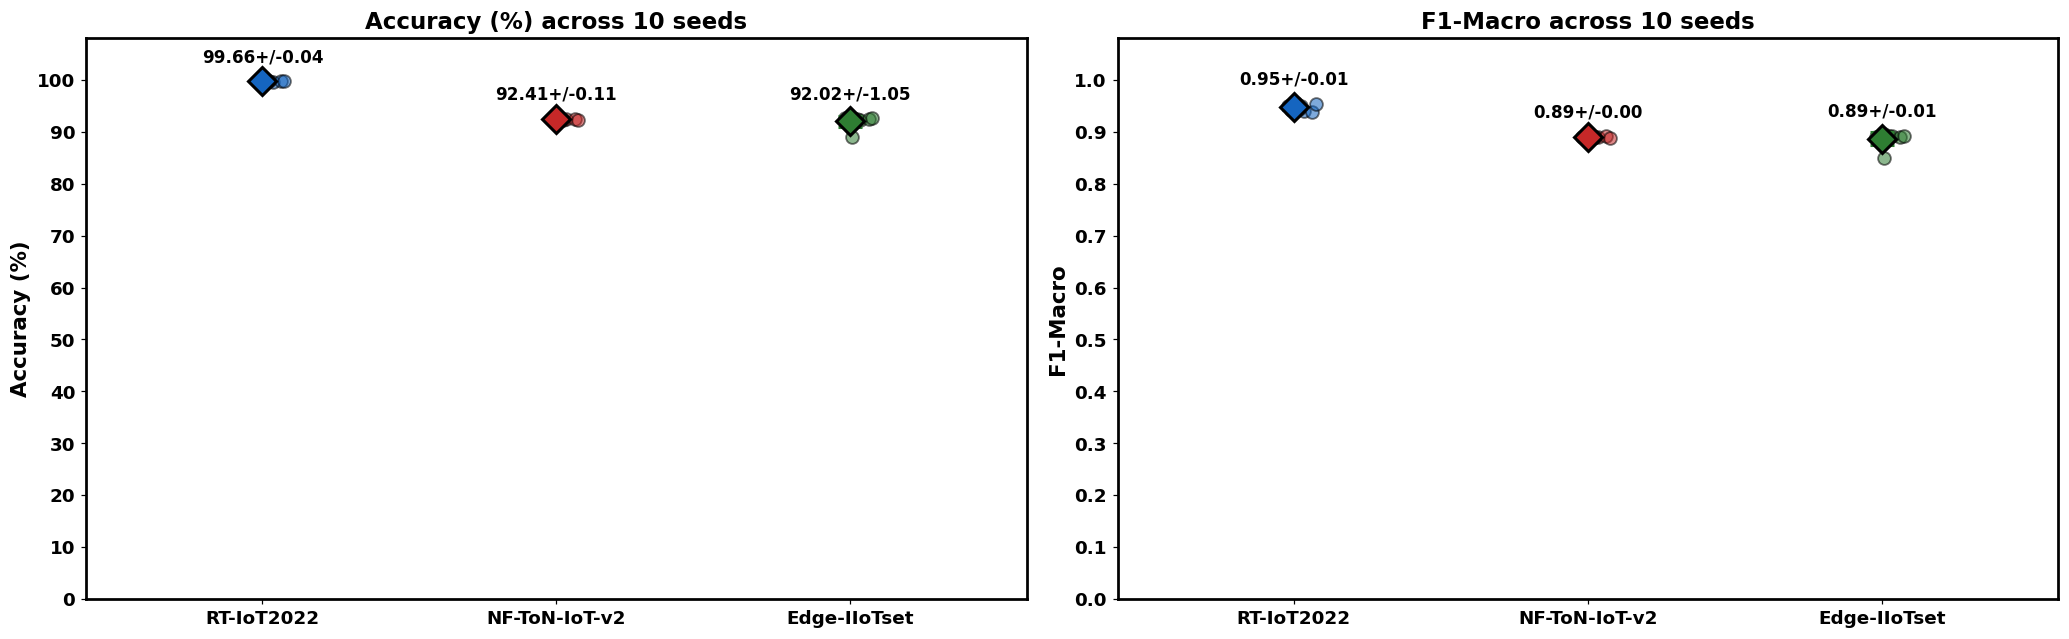

Figure 7. Seed stability of accuracy and macro-F1 (diamond = mean +/- std; small points = individual seeds).


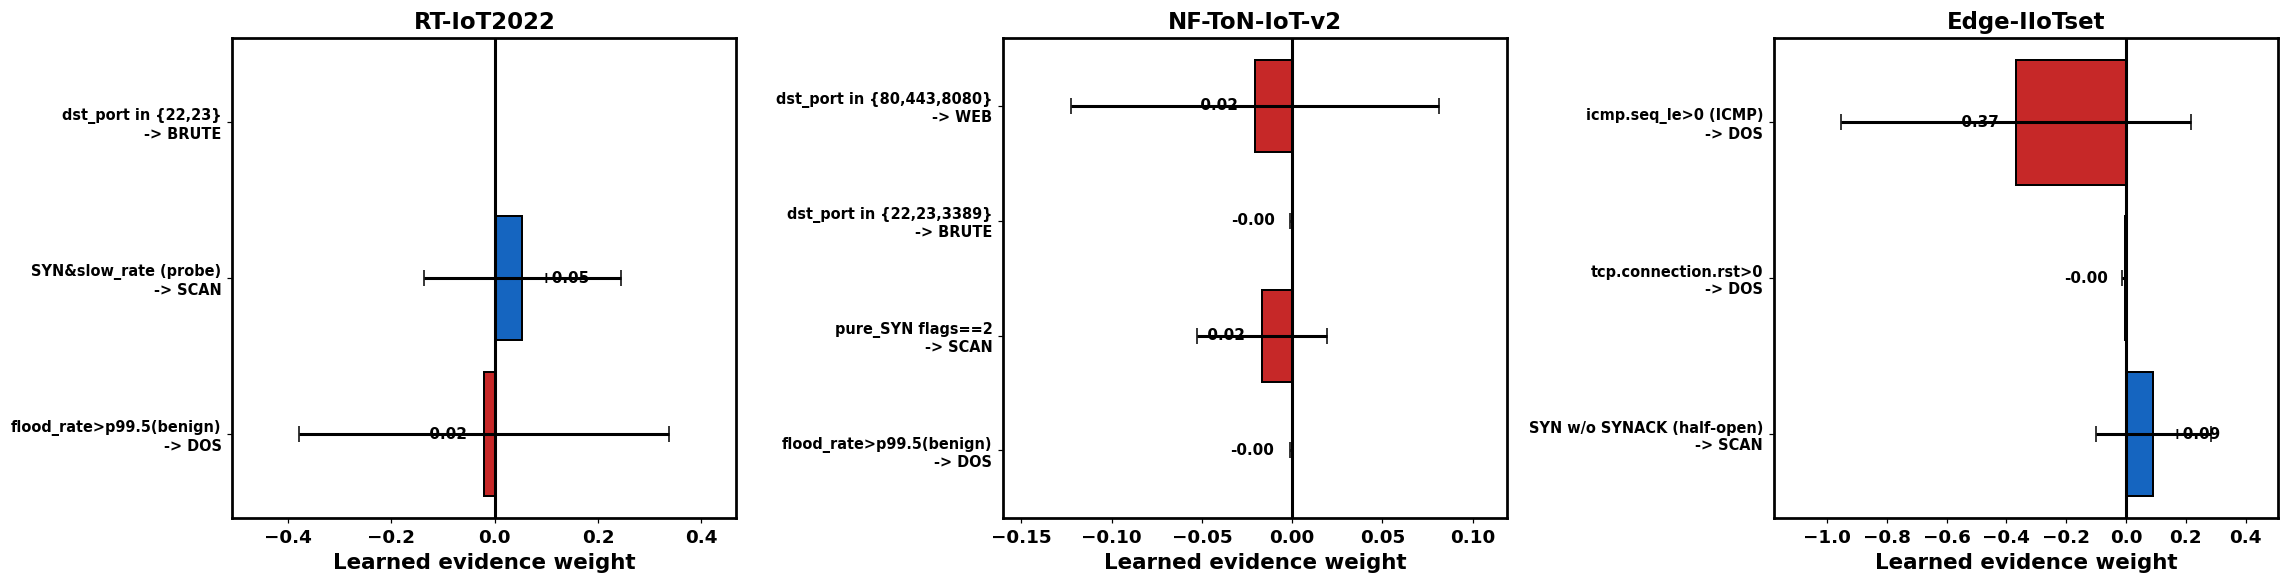

Figure 8. Learned symbolic evidence weights (mean +/- std across seeds). Zero-gated panels indicate the validation gate found no closed-set benefit; negative weights mean the rule fires predominantly outside its target group.
               Classes  Seeds  Accuracy mean  Accuracy std  Precision-M mean  Precision-M std  Recall-M mean  Recall-M std  F1-Macro mean  F1-Macro std  F1-Weighted mean  F1-Weighted std  MCC mean  MCC std  ROC-AUC mean  ROC-AUC std  DR/TPR mean  DR/TPR std  FAR/FPR mean  FAR/FPR std  Sym. dF1m Wilcoxon p (F1m)  ZD dAUROC covered  ZD dAUROC control  ZD margin vs best OOD (covered) Deploy variant  Latency (ms/flow)  Params  Deploy size (KB)
Dataset                                                                                                                                                                                                                                                                                                                                   

In [ ]:
# Cell 12 - Figure 7: seed stability | Figure 8: learned rule weights |
#           summary tables + artifact export
# ----------------------------------------------------------------------
print('Cell 12 - Seed stability, learned-weight figure, summary + export')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(19, 6))
cmap = {"RT-IoT2022": "#1565C0", "NF-ToN-IoT-v2": "#C62828", "Edge-IIoTset": "#2E7D32"}
for ax, key, lab in [(a1, "acc", "Accuracy (%)"), (a2, "f1_m", "F1-Macro")]:
    for xi, name in enumerate(EXP):
        v = np.array([run["res"]["Neurosymbolic"][key] for run in EXP[name]], dtype=float)
        v = v * 100 if key == "acc" else v
        ax.errorbar(xi, v.mean(), yerr=v.std(), fmt="D", markersize=13, capsize=8,
                    color=cmap[name], markeredgecolor="black", markeredgewidth=2,
                    elinewidth=2.5, zorder=3)
        jit = (np.random.RandomState(0).rand(len(v)) - .5) * 0.16
        ax.scatter(np.full(len(v), xi) + jit, v, s=70, color=cmap[name], alpha=.55,
                   edgecolor="black", linewidth=1.2, zorder=2)
        ax.annotate(f"{v.mean():.2f}+/-{v.std():.2f}",
                    (xi, min(v.max(), 100 if key == 'acc' else 1.0)),
                    xytext=(0, 12), textcoords="offset points", ha="center",
                    fontweight="bold", fontsize=11, clip_on=False)
    ax.set_xticks(range(len(EXP))); ax.set_xticklabels(EXP.keys(), fontweight="bold")
    ax.set_xlim(-0.6, len(EXP) - 0.4)
    if key == "acc":
        ax.set_ylim(0, 108); ax.set_yticks(range(0, 101, 10))
    else:
        ax.set_ylim(0, 1.08); ax.set_yticks(np.arange(0, 1.01, 0.1))
    ax.set_ylabel(lab); ax.set_title(f"{lab} across {N_SEEDS} seeds"); bold_ticks(ax)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig7_seed_stability.png"); plt.show()
print("Figure 7. Seed stability of accuracy and macro-F1 (diamond = mean +/- std; "
      "small points = individual seeds).")

fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
for ax, name in zip(axes, EXP):
    eng = ENGINES[name]
    W = np.array([run["w"] for run in EXP[name]], dtype=float)   # (seeds, rules)
    mu, sd = W.mean(0), W.std(0)
    ax.set_yticks(range(len(mu)))
    ax.set_yticklabels([f"{n}\n-> {g}" for n, g in zip(eng.rule_names, eng.rule_groups)],
                       fontsize=9.5, fontweight="bold")
    ax.axvline(0, color="black", linewidth=2)
    ax.set_xlabel("Learned evidence weight"); ax.set_title(name); bold_ticks(ax)
    if np.all(np.abs(mu) + sd < 1e-6):                    # all weights gated to zero
        ax.set_xlim(-1, 1)
        ax.text(0, (len(mu) - 1) / 2, "all rule weights gated to 0\n(no closed-set contribution)",
                ha="center", va="center", fontsize=12, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.5", facecolor="#ECEFF1",
                          edgecolor="black", linewidth=1.5))
        continue
    colors = ["#1565C0" if m >= 0 else "#C62828" for m in mu]
    ax.barh(range(len(mu)), mu, xerr=sd, color=colors, edgecolor="black",
            linewidth=1.3, capsize=5, error_kw=dict(lw=2, ecolor="black"))
    lo = min(0.0, float((mu - sd).min())); hi = max(0.0, float((mu + sd).max()))
    pad = (hi - lo) * 0.18 + 1e-3
    ax.set_xlim(lo - pad, hi + pad)
    for yi, (m, s_) in enumerate(zip(mu, sd)):
        if abs(m) + s_ < 1e-6: continue
        ax.annotate(f"{m:+.2f}", (m + (pad * .25 if m >= 0 else -pad * .25), yi),
                    va="center", ha="left" if m >= 0 else "right",
                    fontweight="bold", fontsize=10, clip_on=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig8_learned_rule_weights.png"); plt.show()
print("Figure 8. Learned symbolic evidence weights (mean +/- std across seeds). "
      "Zero-gated panels indicate the validation gate found no closed-set benefit; "
      "negative weights mean the rule fires predominantly outside its target group.")

OOD_TAGS = ["MSP", "ODIN (T=1000)", "Mahalanobis", "Energy (neural)"]
rows = []
for name in EXP:
    p = PROF[name]
    row = {"Dataset": name, "Classes": len(DATA[name]["classes"]), "Seeds": len(EXP[name])}
    for k, lab in METRIC_KEYS:
        mu, sd = agg(name, "Neurosymbolic", k)
        row[f"{lab} mean"], row[f"{lab} std"] = round(mu, 4), round(sd, 4)
    if "det_tpr" in EXP[name][0]["res"]["Neurosymbolic"]:      # multi-seed DR/FAR if recorded
        for k, lab in [("det_tpr", "DR/TPR"), ("det_fpr", "FAR/FPR")]:
            mu, sd = agg(name, "Neurosymbolic", k)
            row[f"{lab} mean"], row[f"{lab} std"] = round(mu, 4), round(sd, 4)
    mu_n, _ = agg(name, "Neural", "f1_m"); mu_s, _ = agg(name, "Neurosymbolic", "f1_m")
    def zd_gain(kind):
        if not len(ZD_DF): return np.nan
        sub = ZD_DF[(ZD_DF.Dataset == name) & (ZD_DF.Kind == kind)]
        if not len(sub): return np.nan
        return (sub["Energy + symbolic evid. AUROC"].mean()
                - sub["Energy (neural) AUROC"].mean())
    def zd_vs_best_ood(kind):
        # margin of ours over the STRONGEST OOD baseline on the same holdouts
        if not len(ZD_DF): return np.nan
        sub = ZD_DF[(ZD_DF.Dataset == name) & (ZD_DF.Kind == kind)]
        if not len(sub): return np.nan
        best = max(sub[f"{t} AUROC"].mean() for t in OOD_TAGS)
        return sub["Energy + symbolic evid. AUROC"].mean() - best
    zg_cov, zg_ctl = zd_gain("rule-covered"), zd_gain("negative-control")
    zb_cov = zd_vs_best_ood("rule-covered")
    row.update({"Sym. dF1m": round(mu_s - mu_n, 4),
                "Wilcoxon p (F1m)": (round(SIGNIF[name]["f1_m"][0], 4)
                                     if not np.isnan(SIGNIF[name]["f1_m"][0]) else "n/a"),
                "ZD dAUROC covered": round(zg_cov, 4) if not np.isnan(zg_cov) else "n/a",
                "ZD dAUROC control": round(zg_ctl, 4) if not np.isnan(zg_ctl) else "n/a",
                "ZD margin vs best OOD (covered)": round(zb_cov, 4) if not np.isnan(zb_cov) else "n/a",
                "Deploy variant": p["variant"], "Latency (ms/flow)": round(p["lat"], 4),
                "Params": p["params"], "Deploy size (KB)": round(p["size_kb"], 1)})
    rows.append(row)
summary = pd.DataFrame(rows).set_index("Dataset")
pd.set_option("display.width", 260); print(summary.to_string())
summary.to_csv("edgeguard_ns_summary.csv")

per_seed = pd.DataFrame([{"Dataset": n, "Seed": run["seed"], "Tag": tag,
                          **{k: run["res"][tag][k] for k, _ in METRIC_KEYS}}
                         for n in EXP for run in EXP[n] for tag in ("Neural", "Neurosymbolic")])
per_seed.to_csv("edgeguard_ns_per_seed.csv", index=False)

for name, m in MODELS.items():
    torch.save({"state_dict": m.state_dict(), "fusion_w": FUSIONS[name].w.detach().tolist(),
                "rules": ENGINES[name].rule_names, "classes": list(DATA[name]["classes"]),
                "features": DATA[name]["feat_names"]}, f"edgeguard_ns_{name}.pt")

print(f"\n{'-'*80}")
for name in EXP:
    mu, sd = agg(name, "Neurosymbolic", "f1_m")
    print(f"{name:15s} F1-Macro = {mu:.4f}+/-{sd:.4f} | "
          f"accuracy = {agg(name,'Neurosymbolic','acc')[0]*100:.2f}% | "
          f"deployed {PROF[name]['variant']} @ {PROF[name]['lat']:.3f} ms/flow (single thread)")
print("All results are reported as measured - no target-driven adjustment was applied.")
print("Figures -> ./figures | CSVs: summary, per-seed, baselines, zero-day | models -> .pt")
print('Cell 12 - Seed stability, learned-weight figure, summary + export is complete')


Cell 13 - Confusion-derived rates (TP/TN/FP/FN, TPR/TNR/FPR/FNR, DR/FAR)

RT-IoT2022: binary attack-vs-benign (rep seed 42, neurosymbolic)
  TP=22,105  FN=17  FP=19  TN=2,483
  Detection Rate (TPR)=0.9992  False Alarm Rate (FPR)=0.0076  TNR=0.9924  FNR=0.0008  PPV=0.9991  NPV=0.9932

NF-ToN-IoT-v2: binary attack-vs-benign (rep seed 42, neurosymbolic)
  TP=125,051  FN=417  FP=975  TN=19,025
  Detection Rate (TPR)=0.9967  False Alarm Rate (FPR)=0.0488  TNR=0.9513  FNR=0.0033  PPV=0.9923  NPV=0.9786

Edge-IIoTset: binary attack-vs-benign (rep seed 42, neurosymbolic)
  TP=25,625  FN=0  FP=0  TN=4,821
  Detection Rate (TPR)=1.0000  False Alarm Rate (FPR)=0.0000  TNR=1.0000  FNR=0.0000  PPV=1.0000  NPV=1.0000

Per-class one-vs-rest rates (first rows):
   Dataset                      Class  Support    TP  FN  FP    TN    TPR    TNR    FPR    FNR    PPV    NPV
RT-IoT2022             ARP_poisioning     1550  1534  16  20 23054 0.9897 0.9991 0.0009 0.0103 0.9871 0.9993
RT-IoT2022             DDO

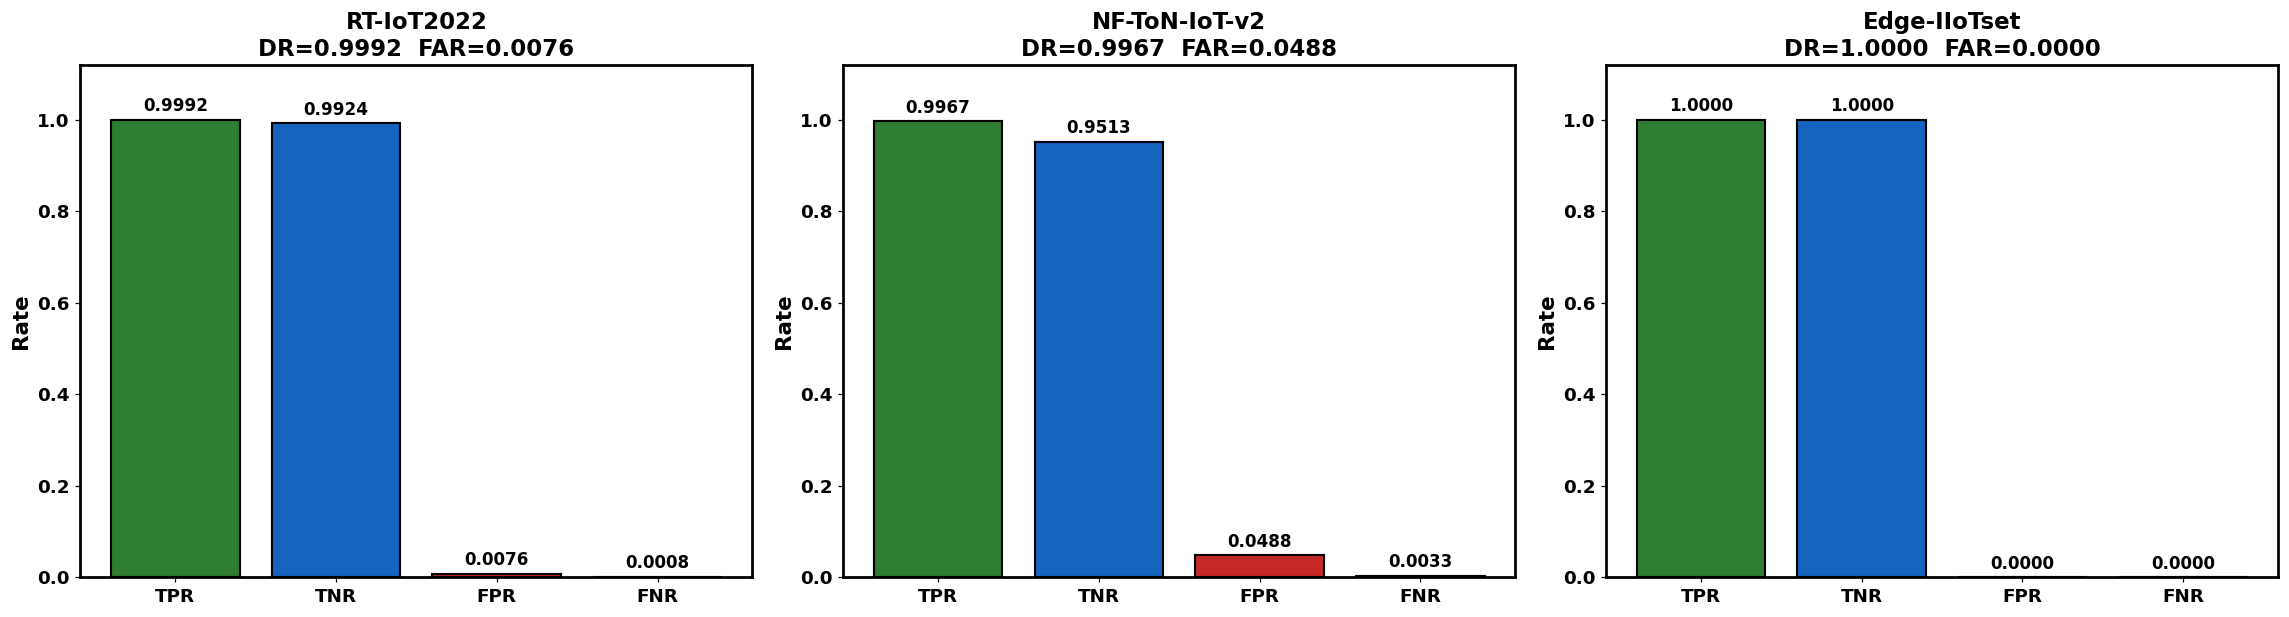

Figure 9. Binary attack-vs-benign detection rates (fixed reference seed).
Cell 13 - Confusion-derived rates is complete


In [ ]:
# Cell 13 - Confusion-derived rates: TP/TN/FP/FN, TPR/TNR/FPR/FNR (+PPV/NPV),
#           per class and binary attack-vs-benign (Detection Rate / False Alarm Rate)
# ----------------------------------------------------------------------------------
print('Cell 13 - Confusion-derived rates (TP/TN/FP/FN, TPR/TNR/FPR/FNR, DR/FAR)')

def rates_from_counts(tp, fn, fp, tn):
    return dict(TP=int(tp), FN=int(fn), FP=int(fp), TN=int(tn),
                TPR=tp/(tp+fn) if tp+fn else np.nan,      # sensitivity / recall / detection rate
                TNR=tn/(tn+fp) if tn+fp else np.nan,      # specificity
                FPR=fp/(fp+tn) if fp+tn else np.nan,      # false-alarm rate
                FNR=fn/(fn+tp) if fn+tp else np.nan,      # miss rate
                PPV=tp/(tp+fp) if tp+fp else np.nan,      # precision
                NPV=tn/(tn+fn) if tn+fn else np.nan)

PERCLASS_ROWS, BIN_ROWS = [], []
for name, d in DATA.items():
    y, pred = d["yte"], RESULTS_REP[name]["Neurosymbolic"]["pred"]
    cm = confusion_matrix(y, pred); total = cm.sum()
    for i, cls in enumerate(d["classes"]):                 # one-vs-rest per class
        tp = cm[i, i]; fn = cm[i].sum() - tp; fp = cm[:, i].sum() - tp
        PERCLASS_ROWS.append({"Dataset": name, "Class": cls, "Support": int(cm[i].sum()),
                              **rates_from_counts(tp, fn, fp, total - tp - fn - fp)})
    is_att_true = np.array([class_to_group(c) != "BENIGN" for c in d["classes"]])[y]
    is_att_pred = np.array([class_to_group(c) != "BENIGN" for c in d["classes"]])[pred]
    tp = int(( is_att_true &  is_att_pred).sum()); fn = int(( is_att_true & ~is_att_pred).sum())
    fp = int((~is_att_true &  is_att_pred).sum()); tn = int((~is_att_true & ~is_att_pred).sum())
    r = rates_from_counts(tp, fn, fp, tn)
    r["Accuracy"] = (tp + tn) / total
    BIN_ROWS.append({"Dataset": name, **r})
    print(f"\n{name}: binary attack-vs-benign (rep seed {REP_SEED}, neurosymbolic)")
    print(f"  TP={tp:,}  FN={fn:,}  FP={fp:,}  TN={tn:,}")
    print(f"  Detection Rate (TPR)={r['TPR']:.4f}  False Alarm Rate (FPR)={r['FPR']:.4f}  "
          f"TNR={r['TNR']:.4f}  FNR={r['FNR']:.4f}  PPV={r['PPV']:.4f}  NPV={r['NPV']:.4f}")

perclass = pd.DataFrame(PERCLASS_ROWS).round(4); binary = pd.DataFrame(BIN_ROWS).round(4)
print("\nPer-class one-vs-rest rates (first rows):"); print(perclass.head(12).to_string(index=False))
perclass.to_csv("perclass_confusion_rates.csv", index=False)
binary.to_csv("binary_detection_rates.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(21, 5.8))
for ax, row in zip(axes, BIN_ROWS):
    keys = ["TPR", "TNR", "FPR", "FNR"]
    vals = [row[k] for k in keys]
    cols = ["#2E7D32", "#1565C0", "#C62828", "#F9A825"]
    b = ax.bar(keys, vals, color=cols, edgecolor="black", linewidth=1.4)
    ax.bar_label(b, fmt="%.4f", fontweight="bold", fontsize=11, padding=3)
    ax.set_ylim(0, 1.12); ax.set_ylabel("Rate")
    ax.set_title(f"{row['Dataset']}\nDR={row['TPR']:.4f}  FAR={row['FPR']:.4f}")
    bold_ticks(ax)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig9_detection_rates.png"); plt.show()
print("Figure 9. Binary attack-vs-benign detection rates (fixed reference seed).")
print('Cell 13 - Confusion-derived rates is complete')


In [ ]:
# Cell 14 - Component ablation (reviewer 1, comment 2)
#   Closed set: same backbone + split per seed, only the fusion layer changes:
#     (a) neural  (b) rules, no gates  (c) entropy gate only  (d) validation gate only  (e) full LSEF
#   Open set (MSP base, all zero-day runs):
#     (f) MSP  (g) evidence with uniform rule weights  (h) benign-rarity evidence,
#     AUROC guard only  (i) full double-guarded channel
#   Worst dAUROC = most negative per-holdout mean change vs MSP (what the guards bound).
# ---------------------------------------------------------------------------------------
print('Cell 14 - Component ablation')
def abl_val(run, src, key):
    # src = "Neural" / "Neurosymbolic" (main run) or an ablation tag
    return run["res"][src][key] if src in run["res"] else run["abl"][src][key]

CCFG = [("(a) Neural", "Neural"), ("(b) rules, no gates", "no_gates"),
        ("(c) entropy gate only", "entropy_only"), ("(d) validation gate only", "valgate_only"),
        ("(e) full LSEF", "Neurosymbolic")]
rows = []
for name in EXP:
    if not EXP[name][0].get("abl"):
        print(f"{name}: no ablation recorded (RUN_ABLATION=False)"); continue
    for lab, src in CCFG:
        f1 = np.array([abl_val(r, src, "f1_m") for r in EXP[name]])
        ac = np.array([abl_val(r, src, "acc")  for r in EXP[name]])
        rows.append(dict(Dataset=name, Config=lab, F1m_mean=f1.mean(), F1m_std=f1.std(),
                         Acc_mean=ac.mean(), Acc_std=ac.std()))
ABL_CLOSED = pd.DataFrame(rows)
if len(ABL_CLOSED):
    print(ABL_CLOSED.pivot(index="Config", columns="Dataset", values="F1m_mean").round(4).to_string())
    # paired test: ungated fusion vs neural (does removing the gates hurt?)
    for name in EXP:
        if not EXP[name][0].get("abl"): continue
        a = np.array([r["res"]["Neural"]["f1_m"] for r in EXP[name]])
        b = np.array([r["abl"]["no_gates"]["f1_m"] for r in EXP[name]])
        try:    wp = wilcoxon(a, b).pvalue
        except ValueError: wp = np.nan
        print(f"   {name:15s} (b)-(a) macro-F1 delta={np.mean(b-a):+.4f}  Wilcoxon p={wp:.4f}  "
              f"min over seeds={np.min(b-a):+.4f}")
    ABL_CLOSED.to_csv("ablation_closed_set.csv", index=False)

orow = []
OCFG = [("(f) MSP", "MSP"), ("(g) evidence, uniform v", "MSP + evid. [uniform v]"),
        ("(h) evidence, AUROC guard only", "MSP + evid. [AUROC guard]"),
        ("(i) full channel", "MSP + symbolic evid.")]
for lab, tag in OCFG:
    if f"{tag} AUROC" not in ZD_DF: continue
    cols = list(dict.fromkeys([f"{tag} AUROC", "MSP AUROC", f"{tag} R@95TNR", "MSP R@95TNR"]))
    per_h = ZD_DF.groupby(["Dataset", "Holdout"])[cols].mean()
    orow.append({"Config": lab, "Mean AUROC": ZD_DF[f"{tag} AUROC"].mean(),
                 "Mean R@95TNR": ZD_DF[f"{tag} R@95TNR"].mean(),
                 "Worst dAUROC (holdout mean)": (per_h[f"{tag} AUROC"] - per_h["MSP AUROC"]).min(),
                 "Worst dR@95 (holdout mean)": (per_h[f"{tag} R@95TNR"] - per_h["MSP R@95TNR"]).min(),
                 "Worst dR@95 (single run)": (ZD_DF[f"{tag} R@95TNR"] - ZD_DF["MSP R@95TNR"]).min()})
ABL_OPEN = pd.DataFrame(orow)
print(ABL_OPEN.round(4).to_string(index=False))
ABL_OPEN.to_csv("ablation_open_set.csv", index=False)
print('Cell 14 - Component ablation is complete')

Cell 14 - Component ablation
Dataset                   Edge-IIoTset  NF-ToN-IoT-v2  RT-IoT2022
Config                                                           
(a) Neural                      0.8862         0.8895      0.9468
(b) rules, no gates             0.8854         0.8894      0.9468
(c) entropy gate only           0.8857         0.8894      0.9468
(d) validation gate only        0.8864         0.8895      0.9468
(e) full LSEF                   0.8863         0.8894      0.9468
   RT-IoT2022      (b)-(a) macro-F1 delta=+0.0000  Wilcoxon p=1.0000  min over seeds=+0.0000
   NF-ToN-IoT-v2   (b)-(a) macro-F1 delta=-0.0000  Wilcoxon p=0.6250  min over seeds=-0.0002
   Edge-IIoTset    (b)-(a) macro-F1 delta=-0.0007  Wilcoxon p=0.2324  min over seeds=-0.0038
                        Config  Mean AUROC  Mean R@95TNR  Worst dAUROC (holdout mean)  Worst dR@95 (holdout mean)  Worst dR@95 (single run)
                       (f) MSP      0.9050        0.5467                       0.0000     

In [ ]:
# Cell 15 - Softmax calibration and the entropy gate (reviewer 2, minor 1)
#   Expected calibration error (15 equal-width bins) of the reference-seed
#   backbone on test data, before and after temperature scaling (T fitted on the
#   held-out validation split by NLL). LSEF is then re-fitted on temperature-
#   scaled logits to check whether calibration changes the fused result.
# ----------------------------------------------------------------------------
print('Cell 15 - Calibration (ECE) and temperature-scaled LSEF')

def ece(probs, y, bins=15):
    conf, pred = probs.max(1), probs.argmax(1)
    edges = np.linspace(0, 1, bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs((pred[m] == y[m]).mean() - conf[m].mean())
    return e

def fit_temperature(lg, y):
    t = torch.zeros(1, requires_grad=True)            # T = exp(t) > 0
    lg, y = torch.tensor(lg), torch.tensor(y)
    opt = torch.optim.LBFGS([t], lr=0.1, max_iter=200)
    def step():
        opt.zero_grad(); loss = nn.functional.cross_entropy(lg / t.exp(), y); loss.backward(); return loss
    opt.step(step); return float(t.exp())

class Scaled(nn.Module):                               # model wrapper: logits / T
    def __init__(self, m, T): super().__init__(); self.m, self.T = m, T
    def forward(self, x): return self.m(x) / self.T

CAL = []
for name, d in DATA.items():
    model = MODELS[name]; model.eval(); va = heldout_idx(d, REP_SEED)
    with torch.no_grad():
        lg_va = model(torch.tensor(d["Xtr"][va], device=DEVICE)).cpu().numpy()
        lg_te = model(torch.tensor(d["Xte"],     device=DEVICE)).cpu().numpy()
    T = fit_temperature(lg_va.astype(np.float64), d["ytr"][va])
    H = lambda lg: (-(softmax_np(lg) * np.log(softmax_np(lg) + 1e-12)).sum(1) / np.log(len(d["classes"])))
    sm = Scaled(model, T)
    fus_T = train_fusion(sm, d, ENGINES[name], REP_SEED, idx=va if CAL_ON_HELDOUT else None)
    res_T = evaluate(name, d, sm, ENGINES[name], fus_T)
    row = dict(Dataset=name, T=T, ECE_raw=ece(softmax_np(lg_te), d["yte"]),
               ECE_T=ece(softmax_np(lg_te / T), d["yte"]),
               meanH_raw=H(lg_te).mean(), meanH_T=H(lg_te / T).mean(),
               F1m_LSEF_raw=RESULTS_REP[name]["Neurosymbolic"]["f1_m"],
               F1m_LSEF_T=res_T["Neurosymbolic"]["f1_m"],
               w_raw=np.round(FUSIONS[name].w.detach().numpy().astype(float), 3).tolist(),
               w_T=np.round(fus_T.w.detach().numpy().astype(float), 3).tolist())
    CAL.append(row)
    print(f"{name:15s} T={T:.3f}  ECE {row['ECE_raw']:.4f} -> {row['ECE_T']:.4f}  "
          f"mean H {row['meanH_raw']:.4f} -> {row['meanH_T']:.4f}  "
          f"LSEF F1m {row['F1m_LSEF_raw']:.4f} -> {row['F1m_LSEF_T']:.4f}  w_T={row['w_T']}")
pd.DataFrame(CAL).to_csv("calibration_ece.csv", index=False)
print('Cell 15 - Calibration (ECE) and temperature-scaled LSEF is complete')

Cell 15 - Calibration (ECE) and temperature-scaled LSEF
RT-IoT2022      T=0.931  ECE 0.0013 -> 0.0011  mean H 0.0054 -> 0.0039  LSEF F1m 0.9518 -> 0.9518  w_T=[0.141, -0.011, 0.0]
NF-ToN-IoT-v2   T=0.912  ECE 0.0395 -> 0.0372  mean H 0.1109 -> 0.1034  LSEF F1m 0.8924 -> 0.8924  w_T=[0.0, 0.0, 0.0, 0.0]
Edge-IIoTset    T=0.667  ECE 0.0287 -> 0.0119  mean H 0.0910 -> 0.0640  LSEF F1m 0.8946 -> 0.8945  w_T=[-0.512, -0.001, -0.582]
Cell 15 - Calibration (ECE) and temperature-scaled LSEF is complete


In [ ]:
# Cell 16 - Results bundle for the revision (all CSVs + figures + run log)
# ------------------------------------------------------------------------
print('Cell 16 - Results bundle')
import zipfile, platform, sklearn, sys
with open("run_info.txt", "w") as fh:
    fh.write(f"python {platform.python_version()} | torch {torch.__version__} | sklearn {sklearn.__version__}\n")
    fh.write(f"device {DEVICE} | cpu {platform.processor() or platform.machine()} | "
             f"CAL_ON_HELDOUT={CAL_ON_HELDOUT} RUN_ABLATION={RUN_ABLATION}\n")
    for name in PROF:
        fh.write(f"{name}: {PROF[name]['reason']}\n")
files = sorted(set(Path(".").glob("*.csv")) | set(FIG_DIR.glob("*.png")) | {Path("run_info.txt")})
with zipfile.ZipFile("results_rev1.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in files: z.write(f)
print(f"{len(files)} files -> {Path('results_rev1.zip').resolve()}")
if "google.colab" in sys.modules:                     # also save a copy to this computer
    from google.colab import files
    files.download("results_rev1.zip")
print('Cell 16 - Results bundle is complete')

Cell 16 - Results bundle
23 files -> /content/EdgeGuardNS_rev1/results_rev1.zip
Cell 16 - Results bundle is complete
